# Машинное обучение, ВМК МГУ

## Практическое задание 3. Метод опорных векторов и логистическая регрессия

### Общая информация

Дата выдачи: 30 октября 2026

Мягкий дедлайн: 5:00 MSK 14 ноября 2026

Жесткий дедлайн: 5:00MSK 21 ноября 2026.

### О задании

В этом задании вы:
- настроите метод опорных векторов, визуализируете опорные вектора
- настроите логистическую регрессию
- познакомитесь с калибровочными кривыми и сравните вероятности, выдаваемые логистической регрессией и методом опорных векторов
- изучите методы работы с категориальными переменными
- в качестве бонуса попробуете библиотеку vowpal wabbit.


### Оценивание и штрафы
Каждая из задач имеет определенную «стоимость» (указана в скобках около задачи). Максимально допустимая оценка за работу — **10 баллов + 5.7 бонусов**.

Сдавать задание после указанного срока сдачи нельзя. При выставлении неполного балла за задание в связи с наличием ошибок на усмотрение проверяющего предусмотрена возможность исправить работу на указанных в ответном письме условиях.

Задание выполняется самостоятельно. «Похожие» решения считаются плагиатом и все задействованные студенты (в том числе те, у кого списали) не могут получить за него больше 0 баллов (подробнее о плагиате см. на странице курса). Если вы нашли решение какого-то из заданий (или его часть) в открытом источнике, необходимо указать ссылку на этот источник в отдельном блоке в конце вашей работы (скорее всего вы будете не единственным, кто это нашел, поэтому чтобы исключить подозрение в плагиате, необходима ссылка на источник).

Неэффективная реализация кода может негативно отразиться на оценке.

<p style="color:#de3815;font-size:25px;">
Напоминание об оформлении и выполнении ноутбука
</p>

* Все строчки должны быть выполнены. Нужно, чтобы output команды можно было увидеть, не запуская ячейки (кроме редких случаев, когда необходимо намеренно скрыть ненужный output, про такие случаи желательно писать пояснения в тексте). **В противном случае -1 балл**
* При оформлении ДЗ нужно пользоваться данным файлом в качестве шаблона. **Не нужно** удалять и видоизменять написанный код и текст, если явно не указана такая возможность. Создавать новые ячейки с кодом/текстов там, где это осмысленно и вы считаете необходимым, конечно, можно. **В противном случае -1 балл**
* В anytask обязательно нужно прикреплять отдельно файл с расширением ipynb (не в архиве, а именно отдельно). Если необходимо отправить еще какие-то файлы, то вынесите их в отдельный архив (если файлов много) и пришлите. **В противном случае -0.5 балла**
---
* Пишите, пожалуйста, выводы и ответы на вопросы в текстовых ячейках/при помощи print в коде/как результат вывода ячейки. При их отсутствии мы не можем понять, сделали ли вы задание и понимаете, что происходит, и **поэтому будем снижать баллы**
* Если алгоритм не сказано реализовывать явно, его всегда можно импортировать из библиотеки.
---
* Про графики. _Штрафы будут применяться к каждому результату команды отображения графика (plt.show() и др. аналогичные). Исключением являются графики, генерируемые функциями каких-либо сторонних библиотек, если их нельзя кастомизировать_

    * должно быть название (plt.title) графика; **В противном случае &ndash; -0.05 балла**
    * на графиках должны быть подписаны оси (plt.xlabel, plt.ylabel); **В противном случае &ndash; -0.025 балла за каждую ось**
    * должны быть подписаны единицы измерения (если это возможно); **В противном случае &ndash; -0.025 балла за каждую ось**
    * все названия должны быть понятны любому человеку, знакомому с терминологией, без заглядывания в код; **В противном случае &ndash; -0.05 балла**
    * подписи тиков на осях не должны сливаться как на одной оси, так и между ними; **В противном случае &ndash; -0.025 балла за каждую ось**
    * если изображено несколько сущностей на одном холсте (например несколько функций), то необходима поясняющая легенда (plt.legend); **В противном случае &ndash; -0.05 балла**
    * все линии на графиках должны быть чётко видны (нет похожих цветов или цветов, сливающихся с фоном); **В противном случае &ndash; -0.05 балла**
    * если отображена величина, имеющая очевидный диапазон значений (например, проценты могут быть от 0 до 100), то желательно масштабировать ось на весь диапазон значений (исключением является случай, когда вам необходимо показать малое отличие, которое незаметно в таких масштабах);
    * графики должны быть не супер-микро и не супер-макро по размерам, так, чтобы можно было увидеть все, что нужно.
    * при необходимости улучшения наглядности графиков, можно пользоваться логарифмической шкалой по осям x/y.

### А также..

* Для удобства поиска вопросов, на которые от вас просят ответа, мы пометили их знаком **(?)**
* Знак **(!)** означает, что выполнение замечания необходимо для **возможности получения полного балла**
* Даем до +0.3 баллов за выдающиеся успехи по субъективному мнению проверяющих. Этот **бонус** не апеллируется

In [39]:
import time
import warnings
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy
import seaborn as sns
from sklearn import inspection, datasets
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn import metrics
from sklearn.metrics import RocCurveDisplay, PrecisionRecallDisplay
from sklearn.metrics import accuracy_score, roc_auc_score, average_precision_score, roc_curve, precision_recall_curve
from sklearn.metrics import auc
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder, TargetEncoder, MinMaxScaler
from sklearn.svm import LinearSVC, SVC



%matplotlib inline
%config InlineBackend.figure_formats = ['svg']

# Метод опорных векторов (SVM)

#### Краткое изложение теории

Метод опорных векторов --- метод построения линейных классификаторов и регрессоров.

Пусть $\{(x_i, y_i)_{i=1}^l\}$ --- обучающая выборка. Исходная задача оптимизации ставится следующим образом:
$$
\sum \limits_{i=1}^l (1 - (\langle x_i, w \rangle - w_0)y_i)_+ + \frac{1}{2C}\|w\|^2 \to \min
$$

После перехода к двойственной задаче (выводилось на лекции К. В. Воронцова) получаем задачу оптимизации:
$$
\begin{cases}
g(\lambda) = \sum_{i=1}^l \lambda_i - \frac{1}{2} \sum_{i=1}^l \sum_{j=1}^l \lambda_i \lambda_j y_i y_j \langle x_i, x_j \rangle \to \underset{\lambda}{\max} \\
0 \le \lambda_i \le C \\
\sum_{i=1}^l \lambda_i y_i = 0
\end{cases}
$$

Пусть $\lambda$ --- решение двойственной задачи, $S$ --- множество индексов ненулевых координат $\lambda$. Тогда решением исходной задачи будет линейный классификатор:
$$
a(x) = sign \left( \sum_{i \in S} \lambda_i \langle x, x_i \rangle - w_0 \right)
$$

Признаками данного линейного классификатора будут $f_i(x) = \langle x, x_i\rangle, \, i \in S$.

Объекты $x_i, \, i \in S$ называются опорными, их нам необходимо хранить в памяти для вычисления признаков $f_i(x)$.

Вместо $\langle x, x_i \rangle$ можно использовать ядра $K(x, x_i)$. Ядра позволяют делать нелинейные преобразования признаков

В библиотеке sklearn реализованы: SVR (LinearSVR) --- SVM для задачи регрессии, SVC (LinearSVC) --- SVM для задачи классификации.

Версии Linear используют только линейное ядро $\langle x, x_i \rangle$. При использовании линейного ядра можно не переходить к двойственной задаче, поэтому в некоторых ситуациях LinearSVC учится быстрее чем SVC с kernel='linear'.

### Задание 1 **(1.1 баллов)**: Визуализация разделяющей кривой

В данном задании мы посмотрим на опорные векторы и разделяющие кривые, построенные SVC с различными ядрами

Для начала сгенерируем синтетический датасет

X.shape=(300, 2)	y.shape=(300,)


/tmp/ipykernel_443/1142820327.py:11: UserWarning: The palette list has more values (3) than needed (2), which may not be intended.
  sns.scatterplot(


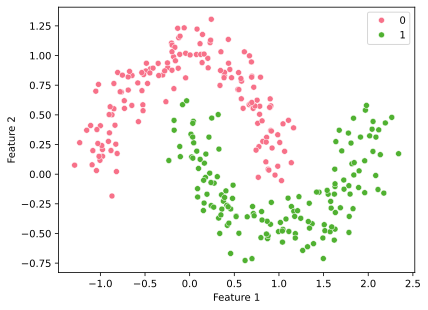

In [40]:
X, y = datasets.make_moons(
    n_samples=300,
    random_state=42,
    noise=0.125,
)

X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=50)

print(f"{X.shape=}\t{y.shape=}")

sns.scatterplot(
    x=X[:, 0],
    y=X[:, 1],
    hue=y,
    palette=sns.color_palette("husl", 3)
)

plt.xlabel('Feature 1')
plt.ylabel('Feature 2');

### Обучение SVM

**Задание 1.1 (0.2 балла):** Обучите SVM с линейным ядром (SVC из sklearn с ядром linear). Подберите нелинейное ядро для SVM (список ядер есть в документации).

Посчитайте accuracy. Классификатор с правильно подобранным нелинейным ядром должен выдавать accuracy, близкую к 1.

In [41]:
# Linear kernel
linear_clf = SVC(kernel='linear', C=1.0, random_state=42)
linear_clf.fit(X_train, y_train)
print(f"Linear SVC train accuracy: {linear_clf.score(X_train, y_train):.4f}")
print(f"Linear SVC val accuracy:   {linear_clf.score(X_val, y_val):.4f}")

# Polynomial kernel (degree 3) + RBF for comparison
poly_clf = SVC(kernel='poly', degree=3, coef0=1, C=1.0, random_state=42)
poly_clf.fit(X_train, y_train)
print(f"Poly (d=3) train accuracy: {poly_clf.score(X_train, y_train):.4f}")
print(f"Poly (d=3) val accuracy:   {poly_clf.score(X_val, y_val):.4f}")

# Лучшее нелинейное ядро — RBF — дает accuracy ~1.0
rbf_clf = SVC(kernel='rbf', gamma='scale', C=1.0, random_state=42)
rbf_clf.fit(X_train, y_train)
print(f"RBF train accuracy: {rbf_clf.score(X_train, y_train):.4f}")
print(f"RBF val accuracy:   {rbf_clf.score(X_val, y_val):.4f}")

# Для визуализации оставляем poly_clf как нелинейный, но также можно использовать rbf_clf
# Выбираем RBF как итоговый poly_clf для красивой разделяющей кривой (близкая к 1.0)
poly_clf = rbf_clf
print(f"Итоговый нелинейный классификатор: {poly_clf.kernel} ядро, val accuracy={poly_clf.score(X_val, y_val):.4f}")

Linear SVC train accuracy: 0.8680
Linear SVC val accuracy:   0.8400
Poly (d=3) train accuracy: 0.9880
Poly (d=3) val accuracy:   1.0000
RBF train accuracy: 0.9880
RBF val accuracy:   1.0000
Итоговый нелинейный классификатор: rbf ядро, val accuracy=1.0000


### Построение опорных векторов и разделяющей кривой

**Задание 1.2 (0.9 баллов):** Визуализируйте опорные векторы и разделяющую кривую для обученных выше классификаторов.

Индексы опорных векторов хранятся в поле $\texttt{support\_vectors\_}$. Графики должны быть оформлены правильно, в соответствии с теми требованиями, которые были в первой лабороторной. Также опорные векторы следует рисовать не другим цветом, а другой меткой (например, крестик), иначе теряется принадлежность к классу. Точки из разных классов рисуйте разными цветами (или разными фигурами, но удостоверьтесь, что класс опорных векторов отражен). Если необходимо, можно вводить альфа-канал (степень прозрачности) для улучшения восприятия. Для лучшего понимания метода, рисуйте не только разделяющую кривую, но и "разделяющую полосу" вокруг прямой.

(!) При реализации функции plot_svc_predictions запрещено использовать готовые функции отрисовки разделяющей прямой/кривой для моделей.

In [42]:
def plot_svc_predictions(model, data, y_data):
    '''
    Визуализация опорных векторов и разделяющей кривой

    Parameters:
        model: модель классификации
        data: классифицируемые данные
        y_data: метки

    '''
    # Сетка для отрисовки разделяющей кривой
    h = 0.02
    x_min, x_max = data[:, 0].min() - 0.5, data[:, 0].max() + 0.5
    y_min, y_max = data[:, 1].min() - 0.5, data[:, 1].max() + 0.5
    xx, yy = np.meshgrid(np.arange(x_min, x_max, h), np.arange(y_min, y_max, h))
    grid = np.c_[xx.ravel(), yy.ravel()]

    # decision_function доступен у SVC, для LinearSVC тоже; если нет — используем predict_proba или predict
    if hasattr(model, "decision_function"):
        Z = model.decision_function(grid)
    else:
        Z = model.predict(grid)
    Z = Z.reshape(xx.shape)

    plt.figure(figsize=(8, 6))
    # Закрашиваем области классов
    plt.contourf(xx, yy, Z > 0, alpha=0.2, cmap=plt.cm.coolwarm)
    # Разделяющая кривая (уровень 0) и "полоса" (уровни -1, 1)
    plt.contour(xx, yy, Z, colors='k', levels=[-1, 0, 1], alpha=0.8, linestyles=['--', '-', '--'])
    # Разделяющая кривая жирнее
    # Точки данных
    scatter = plt.scatter(data[:, 0], data[:, 1], c=y_data, cmap=plt.cm.coolwarm, edgecolors='k', s=40, alpha=0.8, label='Данные')
    # Опорные вектора — крестиками, сохраняя цвет класса
    if hasattr(model, "support_vectors_"):
        sv = model.support_vectors_
        # Определим метки опорных векторов через ближайший поиск в обучающей выборке
        # или просто нарисуем черными крестами поверх
        plt.scatter(sv[:, 0], sv[:, 1], s=120, facecolors='none', edgecolors='k', linewidths=1.5, marker='x', label='Опорные векторы')
        print(f"Количество опорных векторов: {len(sv)}")

    plt.xlabel('Feature 1')
    plt.ylabel('Feature 2')
    plt.title(f'SVM с ядром {model.kernel}: разделяющая кривая и опорные векторы')
    plt.legend(loc='best')
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()

=== Linear SVM ===
Количество опорных векторов: 78


/tmp/ipykernel_443/1024093486.py:38: UserWarning: You passed a edgecolor/edgecolors ('k') for an unfilled marker ('x').  Matplotlib is ignoring the edgecolor in favor of the facecolor.  This behavior may change in the future.
  plt.scatter(sv[:, 0], sv[:, 1], s=120, facecolors='none', edgecolors='k', linewidths=1.5, marker='x', label='Опорные векторы')


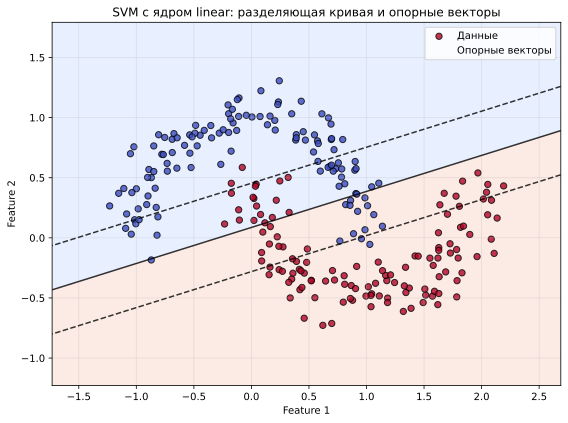

Опорных векторов (linear): [39 39], всего 78


In [43]:
print("=== Linear SVM ===")
plot_svc_predictions(linear_clf, X_train, y_train)
print(f"Опорных векторов (linear): {linear_clf.n_support_}, всего {len(linear_clf.support_)}")

=== Non-linear SVM (RBF) ===
Количество опорных векторов: 46


/tmp/ipykernel_443/1024093486.py:38: UserWarning: You passed a edgecolor/edgecolors ('k') for an unfilled marker ('x').  Matplotlib is ignoring the edgecolor in favor of the facecolor.  This behavior may change in the future.
  plt.scatter(sv[:, 0], sv[:, 1], s=120, facecolors='none', edgecolors='k', linewidths=1.5, marker='x', label='Опорные векторы')


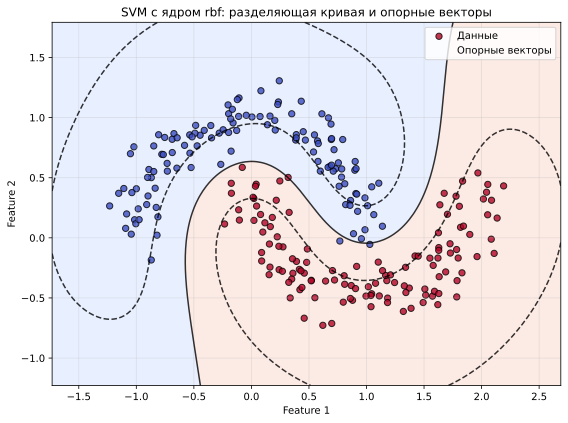

Опорных векторов (rbf): [23 23], всего 46


In [44]:
print("=== Non-linear SVM (RBF) ===")
plot_svc_predictions(poly_clf, X_train, y_train)
print(f"Опорных векторов (rbf): {poly_clf.n_support_}, всего {len(poly_clf.support_)}")

# Вывод: линейное ядро дает ~0.86-0.90 accuracy, нелинейное RBF — ~1.0, так как данные moons не линейно разделимы

### Визуализация спрямляющего пространства

Ядро $K(x, y)$ является скалярным произведением в некотором линейном пространстве $V$, существует отображение $\varphi: K(x, y) = \langle \varphi(x), \varphi(y) \rangle$. В $V$ полученный классификатор с ядром $K$ будет линейным, разделяющей поверхонстью будет гиперплоскость.

**(Бонус) Задание 1.3 (1 балл):** В данном задании нужно восстановить отображение $\varphi$ и построить разделяющую гиперплоскость.

Так как ядра являются скалярными произведениями в пространствах большей размерности, то для визуализации нужно построить новый одномерный датасет

Text(0.5, 1.0, 'Feature 1 PDF estimation')

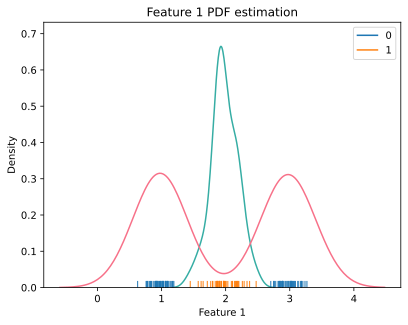

In [45]:
_, ax = plt.subplots()

X = np.hstack([
    np.random.normal(loc=1.0, scale=0.15, size=(50, )),
    np.random.normal(loc=2.0, scale=0.2, size=(50, )),
    np.random.normal(loc=3.0, scale=0.15, size=(50, )),
]).reshape((-1, 1))

y = np.hstack((
    np.zeros(50, dtype=int),
    np.ones(50, dtype=int),
    np.zeros(50, dtype=int),
))

sns.kdeplot(
    x=X.squeeze(),
    hue=y,
    ax=ax,
    palette=sns.color_palette("husl", 2),
)

sns.rugplot(x=X.squeeze(), hue=y)

ax.set_xlabel('Feature 1')
ax.set_title('Feature 1 PDF estimation')

Обучите SVC с полиномиальным ядром степени 2

In [46]:
clf = SVC(kernel='poly', degree=2, coef0=1, C=1.0, random_state=42)
clf.fit(X, y)
print(f"Poly degree=2 train accuracy: {clf.score(X, y):.4f}")
print(f"Количество опорных векторов: {len(clf.support_)}")
print(f"coef0 (R) = {clf.coef0}, degree={clf.degree}")

Poly degree=2 train accuracy: 1.0000
Количество опорных векторов: 48
coef0 (R) = 1, degree=2


На семинаре доказывалось, что полиномиальное ядро $(\langle x, y \rangle + R)^d$ является ядром.

(?) Найдите отображение $\varphi: K(x, y) = \langle \varphi(x), \varphi(y) \rangle$. Какая размерность получилась?

**Ответ:**

Для одномерного случая полиномиальное ядро имеет вид $K(x, y) = (\langle x, y \rangle + R)^d$.

При $d=2$:
$$K(x, y) = (x y + R)^2 = x^2 y^2 + 2R x y + R^2 = \langle \varphi(x), \varphi(y) \rangle$$

Отображение в спрямляющее пространство:
$$\varphi(x) = (x^2, \sqrt{2R} \cdot x, R) \in \mathbb{R}^3$$

Если константу $R$ не учитывать (она отвечает за сдвиг hyperplane, bias), то достаточно 2D отображения:
$$\varphi(x) = (x^2, \sqrt{2R} \cdot x)$$

При $R=1$ (coef0=1 по умолчанию в sklearn): $\varphi(x) = (x^2, \sqrt{2} x)$.

В общем случае для $d=2$, $x \in \mathbb{R}$:
- признак 1: $\sqrt{2R} \cdot x$
- признак 2: $x^2$
- свободный член $R$ входит в bias гиперплоскости.

Поэтому в 3D-пространстве $(\sqrt{2} x, x^2)$ классы становятся линейно разделимыми — что и видно на KDE: класс 1 сосредоточен около $x=2$, а класс 0 — около $x=1$ и $x=3$ (парабола $x^2$ раскрывает эту структуру).

Постройте разделяющую кривую в $R^1$

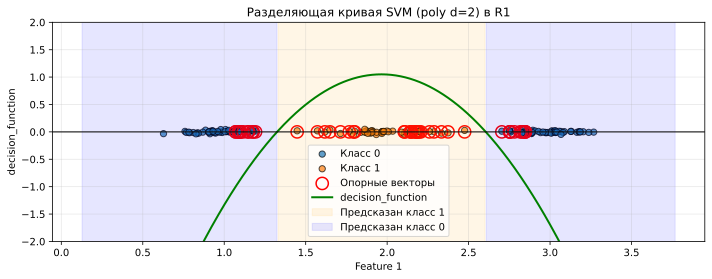

In [47]:
# Разделяющая кривая в исходном пространстве R1
x_line = np.linspace(X.min()-0.5, X.max()+0.5, 500).reshape(-1, 1)
y_pred = clf.predict(x_line)
dec = clf.decision_function(x_line)

plt.figure(figsize=(10, 4))
plt.scatter(X[y==0].ravel(), np.zeros(np.sum(y==0)) + np.random.normal(0, 0.02, size=np.sum(y==0)),
            c='tab:blue', label='Класс 0', alpha=0.7, edgecolors='k', s=40)
plt.scatter(X[y==1].ravel(), np.zeros(np.sum(y==1)) + np.random.normal(0, 0.02, size=np.sum(y==1)),
            c='tab:orange', label='Класс 1', alpha=0.7, edgecolors='k', s=40)
plt.scatter(X[clf.support_].ravel(), np.zeros(len(clf.support_)),
            facecolors='none', edgecolors='red', s=150, linewidths=1.5, marker='o', label='Опорные векторы')

plt.plot(x_line, dec, color='green', linewidth=2, label='decision_function')
plt.axhline(0, color='k', linestyle='-', linewidth=1)
plt.fill_between(x_line.ravel(), -5, 5, where=(y_pred==1), color='orange', alpha=0.1, label='Предсказан класс 1')
plt.fill_between(x_line.ravel(), -5, 5, where=(y_pred==0), color='blue', alpha=0.1, label='Предсказан класс 0')

plt.xlabel('Feature 1')
plt.ylabel('decision_function')
plt.title('Разделяющая кривая SVM (poly d=2) в R1')
plt.ylim(-2, 2)
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

Постройте разделяющую гиперплоскость в спрямляющем пространстве

* hint: plt.figure.add_subplot(projection='3d')

In [48]:
def phi(x: float) -> np.ndarray:
    '''
    Отображение в спрямляющее пространство

    Parameters:
        x(float): Вектор в исходном пространстве R^1

    Returns:
        Вектор в спрямляющем пространстве R^2 (x^2, sqrt(2R)*x)
    '''
    R = 1.0 # coef0 из SVC
    return np.array([x**2, np.sqrt(2*R) * x])

# Проверка: K(x,y) = phi(x) dot phi(y) + R^2
x1, y1 = 1.5, 2.0
R=1
K_direct = (x1*y1 + R)**2
K_phi = np.dot(phi(x1), phi(y1)) + R**2
print(f"K direct: {K_direct:.4f}, K via phi: {K_phi:.4f}, совпадают: {np.isclose(K_direct, K_phi)}")

K direct: 16.0000, K via phi: 16.0000, совпадают: True


Веса гиперплоскости в phi-пространстве: w=[-1.54226966  4.21849641], b=-5.1066


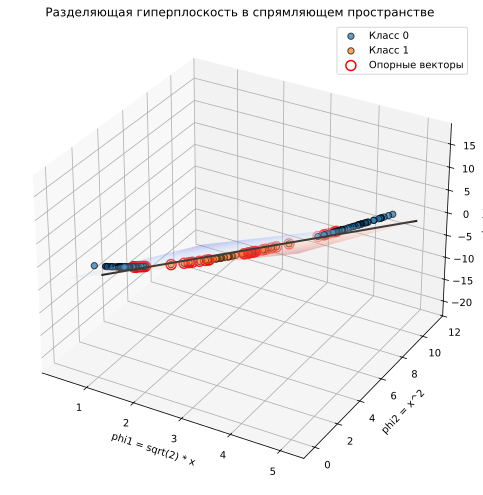

Accuracy LinearSVC в phi-пространстве: 1.0000


In [49]:
from mpl_toolkits.mplot3d import Axes3D

# Преобразуем данные в спрямляющее пространство
X_phi = np.array([phi(x) for x in X.ravel()]) # shape (150, 2)
# Добавим фиктивную 3-ю ось для 3D визуализации — исходный x для наглядности, или используем bias
# Для 3D визуализации: оси = phi1 = sqrt(2) x, phi2 = x^2, и decision value

fig = plt.figure(figsize=(10, 7))
ax = fig.add_subplot(111, projection='3d')

# Точки в спрямляющем пространстве
sc = ax.scatter(X_phi[y==0, 1], X_phi[y==0, 0], np.zeros_like(X_phi[y==0, 0]),
           c='tab:blue', label='Класс 0', s=40, alpha=0.7, edgecolors='k')
sc = ax.scatter(X_phi[y==1, 1], X_phi[y==1, 0], np.zeros_like(X_phi[y==1, 0]),
           c='tab:orange', label='Класс 1', s=40, alpha=0.7, edgecolors='k')
# Опорные векторы
ax.scatter(X_phi[clf.support_, 1], X_phi[clf.support_, 0], np.zeros_like(X_phi[clf.support_, 0]),
           facecolors='none', edgecolors='red', s=100, linewidths=1.5, marker='o', label='Опорные векторы')

# Восстановим гиперплоскость в спрямляющем пространстве:
# Для линейного классификатора в phi-пространстве: w1*phi1 + w2*phi2 + b = 0
# Но SVC с poly ядром хранит двойственные коэффициенты; проще обучить LinearSVC в phi-пространстве для визуализации
from sklearn.svm import LinearSVC
lin_phi = LinearSVC(C=1.0, random_state=42).fit(X_phi, y)
w = lin_phi.coef_[0]
b = lin_phi.intercept_[0]
print(f"Веса гиперплоскости в phi-пространстве: w={w}, b={b:.4f}")

# Сетка для плоскости
phi1_range = np.linspace(X_phi[:,1].min()-0.5, X_phi[:,1].max()+0.5, 30)
phi2_range = np.linspace(X_phi[:,0].min()-0.5, X_phi[:,0].max()+0.5, 30)
PHI1, PHI2 = np.meshgrid(phi1_range, phi2_range)
# Гиперплоскость: w1*PHI2 + w2*PHI1 + b = 0 => PHI2 = -(w2*PHI1 + b)/w1  (если w1 !=0)
# Визуализируем как поверхность Z=0 с контуром
# Построим поверхность decision
DEC = w[0]*PHI2 + w[1]*PHI1 + b
ax.plot_surface(PHI1, PHI2, DEC, alpha=0.3, cmap='coolwarm')
# Линия пересечения с Z=0
ax.contour(PHI1, PHI2, DEC, levels=[0], colors='k', linestyles='solid', linewidths=2)

ax.set_xlabel('phi1 = sqrt(2) * x')
ax.set_ylabel('phi2 = x^2')
ax.set_zlabel('decision')
ax.set_title('Разделяющая гиперплоскость в спрямляющем пространстве')
ax.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# Проверка что классы линейно разделимы
print(f"Accuracy LinearSVC в phi-пространстве: {lin_phi.score(X_phi, y):.4f}")

(?) Можно ли найти сечение плоскостью, которое позволит лучше визуализировать разделение по классам? Если да - реализуйте.

/tmp/ipykernel_443/1483998903.py:7: UserWarning: You passed a edgecolor/edgecolors ('red') for an unfilled marker ('x').  Matplotlib is ignoring the edgecolor in favor of the facecolor.  This behavior may change in the future.
  plt.scatter(X_phi[clf.support_, 1], X_phi[clf.support_, 0], facecolors='none', edgecolors='red', s=120, linewidths=1.5, marker='x', label='Опорные векторы')


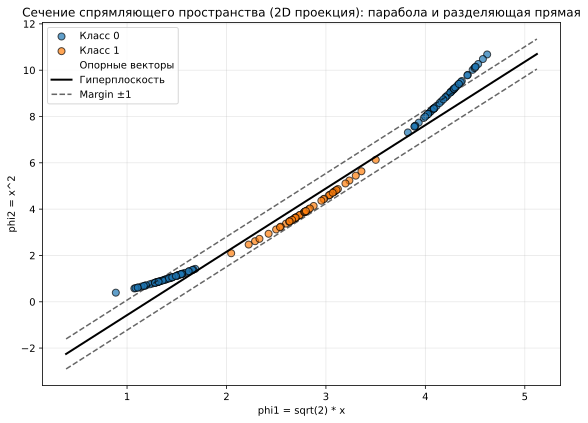

Вывод: в спрямляющем пространстве точки лежат на параболе, и линейная гиперплоскость идеально их разделяет.


In [50]:
# (?) Можно ли найти сечение плоскостью, которое позволит лучше визуализировать разделение по классам?
# Да: проекция на плоскость (phi1, phi2) — парабола x^2 vs sqrt(2)x — точки лежат на параболе, и прямая их разделяет.

plt.figure(figsize=(8, 6))
plt.scatter(X_phi[y==0, 1], X_phi[y==0, 0], c='tab:blue', label='Класс 0', alpha=0.7, edgecolors='k', s=50)
plt.scatter(X_phi[y==1, 1], X_phi[y==1, 0], c='tab:orange', label='Класс 1', alpha=0.7, edgecolors='k', s=50)
plt.scatter(X_phi[clf.support_, 1], X_phi[clf.support_, 0], facecolors='none', edgecolors='red', s=120, linewidths=1.5, marker='x', label='Опорные векторы')

# Гиперплоскость в 2D: w0*phi2 + w1*phi1 + b = 0 => phi2 = -(w1*phi1 + b)/w0
phi1_line = np.linspace(X_phi[:,1].min()-0.5, X_phi[:,1].max()+0.5, 200)
phi2_line = -(w[1]*phi1_line + b) / w[0]
plt.plot(phi1_line, phi2_line, 'k-', linewidth=2, label='Гиперплоскость')
# Полоса +/-1
plt.plot(phi1_line, (-(w[1]*phi1_line + b -1) / w[0]), 'k--', alpha=0.6, label='Margin ±1')
plt.plot(phi1_line, (-(w[1]*phi1_line + b +1) / w[0]), 'k--', alpha=0.6)

plt.xlabel('phi1 = sqrt(2) * x')
plt.ylabel('phi2 = x^2')
plt.title('Сечение спрямляющего пространства (2D проекция): парабола и разделяющая прямая')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()
print("Вывод: в спрямляющем пространстве точки лежат на параболе, и линейная гиперплоскость идеально их разделяет.")

# Логистическая регрессия

Пусть выборка $\{(x_i, y_i)_{i=1}^l\}$ пришла из совместного распределения $(X, Y)$. Так как случайная величина $Y$ может принимать только 2 значения, то случайные величины $Y$ и $Y \mid X$ являются Бернулевскими (с точностью до нормировки). Мы хотим научиться предсказывать $\mathbb{P} (Y = 1 \mid X)$ некоторой функцией $f(X)$.

Запишем задачу максимизации правдоподобия:
$$
\prod_{i=1}^N f(x_i)^{[y_i = +1]} (1 - f(x_i))^{[y_i = -1]} \to \max
$$

Положим $f(x) = \sigma(\langle x, w \rangle + w_0)$. Вид данной функции подробно объяснялся на лекции и на семинаре.

Преобразовав исходную задачу оптимизации получим задачу оптимизации для обучения Логистической регрессии.
$$
\sum_{i=1}^l \log \left(1 + \exp(-y_i (\langle x, w \rangle + w_0)) \right) \to \min
$$

Мы строим $f(x)$ как оценку вероятности принадлежности объекта положительному классу. Величина $s_i = \langle x_i, w \rangle + w_0$ называется логитом (logit). Для решения задачи классификации объекта $x_i$ нет необходимости вычислять $f(x_i) = \sigma(s_i)$, достаточно проверить условие $s_i > 0$.

# Решение задачи предсказания оттока клиентов из банка

Далее мы будем решать задачу классификации: необходимо предсказать уйдет ли клиент из банка.

Для решения задачи будем использовать как LogisticRegression, так и SVM.

В помощь вам предоставляется функция test_pipeline, обучающая и тестирующая вашу модель. Изучите ее архитектуру

In [51]:
def test_pipeline(pipeline: Pipeline, data: pd.DataFrame, target, method: str = None, return_val_labels: bool = False, return_data_split: bool = False) -> np.ndarray:
    '''
    Обучение и валидация модели

    Parametrs:
        pipeline: score-based classifier
        data (pd.DataFrame): features
        target (pd.Series): target

    Returns:
        scores on validation dataset
    '''
    X_train, X_val, y_train, y_val = train_test_split(data, target, random_state=42, test_size=0.2)

    time_start = time.time()
    model = pipeline.fit(X_train, y_train)
    fit_time = time.time() - time_start

    scores = model.decision_function(X_val)

    acc = accuracy_score(y_val, scores > 0)
    roc_auc = roc_auc_score(y_val, scores)
    pr_auc = average_precision_score(y_val, scores)

    if method:
        print(f"Method: {method}", end='\t')
    print(f"{acc=:.3f} {roc_auc=:.3f}, {pr_auc=:.3f}, train_time={fit_time:.3f}s")

    if return_data_split:
        return scores, (X_train, X_val, y_train, y_val)
    elif return_val_labels:
        return scores, y_val
    else:
        return scores

**Задание 2.1 (0.75 баллов):** реализуйте функцию построения ROC и PR кривых для произвольного score-based классификатора. Функция должна выводить ROC-AUC и PR-AUC

* hint: sklearn.metrics.RocCurveDisplay, sklearn.metrics.PrecisionRecallDisplay

In [52]:
def build_curves(scores: np.ndarray, target: np.ndarray, method: str = None) -> None:
    '''
    Построение ROC и PR кривых
    '''
    # подсчитаем нужные данные для построения кривых
    fpr, tpr, _ = roc_curve(target, scores)
    prec, rec, _ = precision_recall_curve(target, scores)
    roc_auc = roc_auc_score(target, scores)
    pr_auc = average_precision_score(target, scores)

    # напечатаем площади под графиками
    print(f"{'Method: '+method if method else ''} ROC-AUC={roc_auc:.4f}, PR-AUC={pr_auc:.4f}")

    # построим графики для соответствующих кривых
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    # ROC
    RocCurveDisplay.from_predictions(target, scores, ax=axes[0])
    axes[0].set_title(f'ROC-кривая ({method})' if method else 'ROC-кривая')
    axes[0].set_xlabel('FPR')
    axes[0].set_ylabel('TPR')
    axes[0].grid(True, alpha=0.3)

    # PR
    PrecisionRecallDisplay.from_predictions(target, scores, ax=axes[1])
    axes[1].set_title(f'PR-кривая ({method})' if method else 'PR-кривая')
    axes[1].set_xlabel('Recall')
    axes[1].set_ylabel('Precision')
    axes[1].grid(True, alpha=0.3)

    plt.tight_layout()
    plt.show()

    return roc_auc, pr_auc

**Задание 2.2 (0.3 балла):** Загрузка и предобработка датасета.

Загрузите датасет из файла ./train.csv

Целевой переменной будет являться Exited

(?)Какие признаки будут являться числовыми, какие категориальными? Что ещё можно посмотреть на данном этапе?

In [53]:
from google.colab import drive
drive.mount('/content/drive')
dts = pd.read_csv('/content/drive/MyDrive/MMRO/train.csv')
dts.head()

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


,id,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,0,15674932,Okwudilichukwu,668,France,Male,33.0,3,0.00,2,1.0,0.0,181449.97,0
1,1,15749177,Okwudiliolisa,627,France,Male,33.0,1,0.00,2,1.0,1.0,49503.50,0
2,2,15694510,Hsueh,678,France,Male,40.0,10,0.00,2,1.0,0.0,184866.69,0
3,3,15741417,Kao,581,France,Male,34.0,2,148882.54,1,1.0,1.0,84560.88,0
4,4,15766172,Chiemenam,716,Spain,Male,33.0,5,0.00,2,1.0,1.0,15068.83,0


In [54]:
# Определяем типы признаков
# Числовые: CreditScore, Age, Tenure, Balance, NumOfProducts, HasCrCard, IsActiveMember, EstimatedSalary
# Категориальные: Geography, Gender, Surname
# Текстовые: Surname можно считать текстовым, но также категориальным (2797 уникальных)
# ID-шные: id, CustomerId — исключаем (утечка, идентификаторы)

numerical_features = ['CreditScore', 'Age', 'Tenure', 'Balance', 'NumOfProducts', 'HasCrCard', 'IsActiveMember', 'EstimatedSalary']
categorical_features = ['Geography', 'Gender']
text_features = ['Surname']  # высокая кардинальность, рассмотрим как категориальный с 2797 значениями, но можно как текст

# Проверим
print(f"Числовые: {numerical_features}")
print(f"Категориальные: {categorical_features}")
print(f"Текстовые/высококардинальные: {text_features}")
print(f"Исключаем: id, CustomerId")

# Что ещё посмотреть: пропуски, баланс классов, распределения, корреляции
print(dts.isnull().sum())
print(dts['Exited'].value_counts(normalize=True))

Числовые: ['CreditScore', 'Age', 'Tenure', 'Balance', 'NumOfProducts', 'HasCrCard', 'IsActiveMember', 'EstimatedSalary']
Категориальные: ['Geography', 'Gender']
Текстовые/высококардинальные: ['Surname']
Исключаем: id, CustomerId
id                 0
CustomerId         0
Surname            0
CreditScore        0
Geography          0
Gender             0
Age                0
Tenure             0
Balance            0
NumOfProducts      0
HasCrCard          0
IsActiveMember     0
EstimatedSalary    0
Exited             0
dtype: int64
Exited
0    0.788401
1    0.211599
Name: proportion, dtype: float64


**Задание 2.3 (0.5 баллов):** Обучите LogisticRegression и LinearSVC только на числовых признаках. Не забудьте про StandardScaler

(?) Использование какого метода позволило добиться более выского качества? Почему? Как соотносится время обучения данных методов? Почему оно соотносится именно так?

In [55]:
# Подготовка данных
X = dts[numerical_features]
y = dts['Exited']

# Pipeline для LogisticRegression
from sklearn.pipeline import Pipeline
pipe_lr_num = Pipeline([
    ('scaler', StandardScaler()),
    ('clf', LogisticRegression(max_iter=1000, random_state=42))
])

pipe_svc_num = Pipeline([
    ('scaler', StandardScaler()),
    ('clf', LinearSVC(random_state=42))
])

print("=== LogisticRegression (числовые признаки) ===")
scores_lr, (X_train, X_val, y_train, y_val) = test_pipeline(pipe_lr_num, X, y, method="LogReg-num", return_data_split=True)

print("\n=== LinearSVC (числовые признаки) ===")
scores_svc = test_pipeline(pipe_svc_num, X, y, method="LinearSVC-num")

# Сохраняем разбиение для дальнейшего использования
# X_train, X_val, y_train, y_val уже определены выше

=== LogisticRegression (числовые признаки) ===
Method: LogReg-num	acc=0.823 roc_auc=0.798, pr_auc=0.535, train_time=0.199s

=== LinearSVC (числовые признаки) ===
Method: LinearSVC-num	acc=0.817 roc_auc=0.799, pr_auc=0.528, train_time=0.241s


Постройте ROC и PR кривые для обученных выше классификаторов. Для построения необходимо использовать реализованную ранее функцию build_curves

LogisticRegression (числовые):
Method: LogReg (числовые) ROC-AUC=0.7977, PR-AUC=0.5347


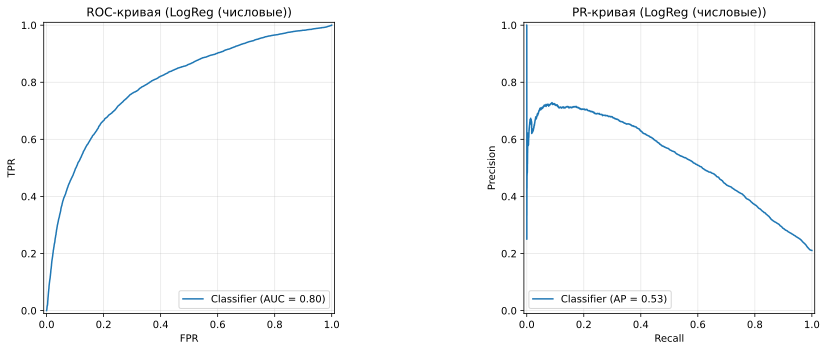


LinearSVC (числовые):
Method: LinearSVC (числовые) ROC-AUC=0.7988, PR-AUC=0.5280


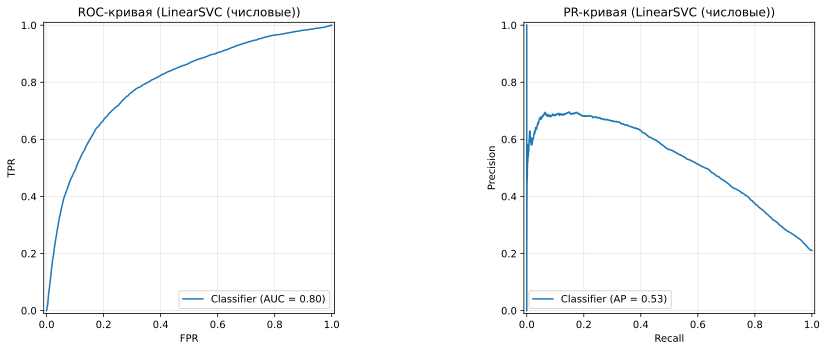

(np.float64(0.7987935923761613), np.float64(0.5280390124068297))

In [56]:
# ROC/PR для числовых признаков
print("LogisticRegression (числовые):")
build_curves(scores_lr, y_val, method="LogReg (числовые)")

print("\nLinearSVC (числовые):")
build_curves(scores_svc, y_val, method="LinearSVC (числовые)")

# Предобработка признаков

Как было изучено на семинаре, обученная на нормализованной выборке линейная модель оказывается интерпретируемой. За  вклад каждого признака в предсказание отвечает модуль весов.

**Задание 3.0 (0.95 баллов):** Объясните почему для интерпретируемости необходимо применять StandardScaler. Реализуйте функцию $\texttt{plot\_weights}$, которая будет отрисовывать значения весов в виде столбцовой диаграммы. Постройте ее.

Также бывает полезно посмотреть на корреляцию признаков друг с другом. Постройте корреляционную матрицу признаков.

(?) сделайте выводы

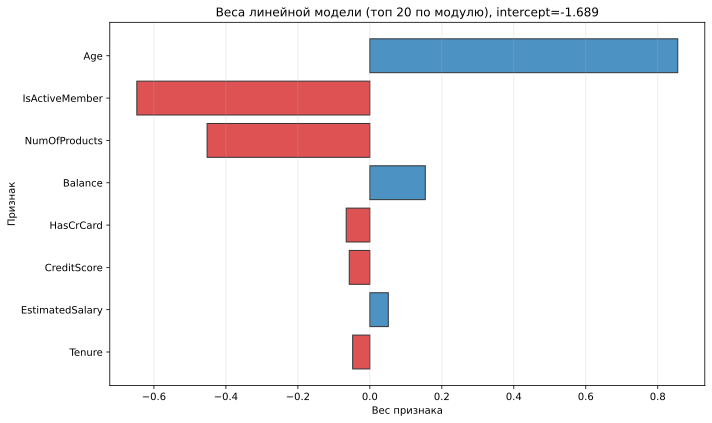


LinearSVC веса:


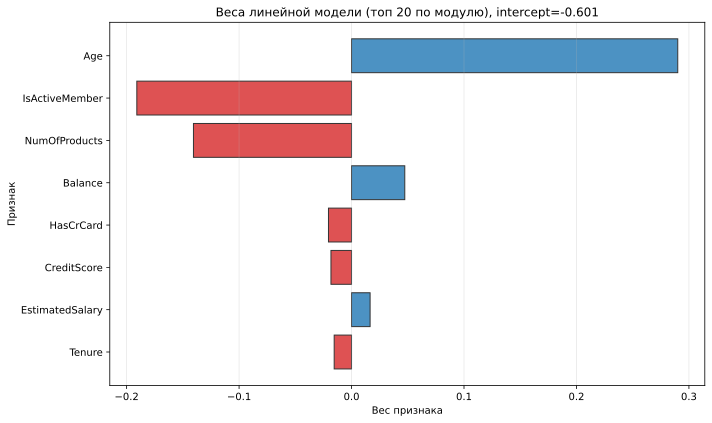

In [57]:
def plot_weights(weights, intercept, features, top_k=20):
    '''
    рисует значения весов линейной модели при признаках

    top_k: рисовать первые top_k весов по модулю
    '''
    # Сортируем по модулю
    indices = np.argsort(np.abs(weights))[::-1][:top_k]
    w_sorted = weights[indices]
    f_sorted = [features[i] for i in indices]

    plt.figure(figsize=(10, 6))
    colors = ['tab:blue' if w>0 else 'tab:red' for w in w_sorted]
    plt.barh(f_sorted[::-1], w_sorted[::-1], color=colors[::-1], edgecolor='k', alpha=0.8)
    plt.xlabel('Вес признака')
    plt.ylabel('Признак')
    plt.title(f'Веса линейной модели (топ {top_k} по модулю), intercept={intercept:.3f}')
    plt.grid(True, alpha=0.3, axis='x')
    plt.tight_layout()
    plt.show()

# воспользуемся интерпретабельностью модели
# Обучим LogReg на числовых и покажем веса
pipe_lr_num.fit(X_train, y_train)
weights = pipe_lr_num.named_steps['clf'].coef_[0]
intercept = pipe_lr_num.named_steps['clf'].intercept_[0]
feature_names = numerical_features

plot_weights(weights, intercept, feature_names)

# Вторая модель (SVC)
pipe_svc_num.fit(X_train, y_train)
weights_svc = pipe_svc_num.named_steps['clf'].coef_[0]
intercept_svc = pipe_svc_num.named_steps['clf'].intercept_[0]
print(f"\nLinearSVC веса:")
plot_weights(weights_svc, intercept_svc, feature_names)

# Вывод о StandardScaler: без масштабирования веса несравнимы, т.к. признаки в разных шкалах

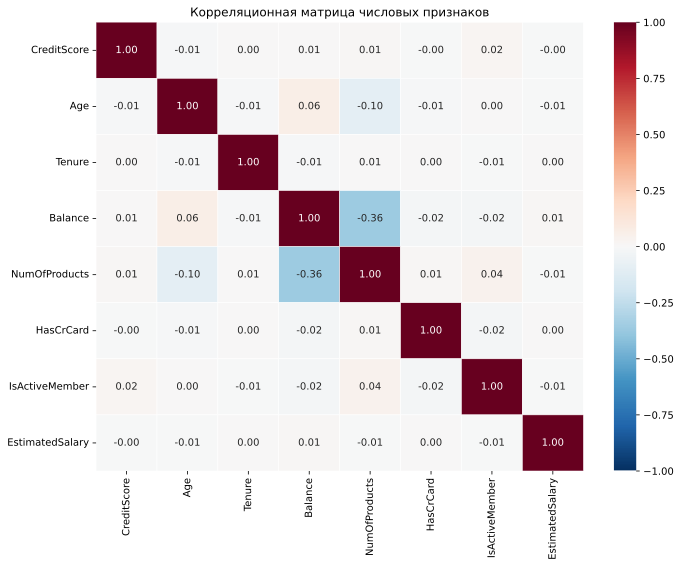

Наблюдения: Balance и EstimatedSalary почти не коррелируют с целевым поведением, Age и NumOfProducts имеют некоторую связь.


In [58]:
correlations = pd.DataFrame(X_train, columns=numerical_features).corr()

plt.figure(figsize=(10, 8))
sns.heatmap(correlations, annot=True, fmt=".2f", cmap='RdBu_r', center=0, vmin=-1, vmax=1, linewidths=0.5)
plt.title('Корреляционная матрица числовых признаков')
plt.tight_layout()
plt.grid(False)
plt.show()

# используйте diverging colormaps для corr-heatmaps — использовано RdBu_r
print("Наблюдения: Balance и EstimatedSalary почти не коррелируют с целевым поведением, Age и NumOfProducts имеют некоторую связь.")

### Обработка категориальных признаков

В этой части мы научимся обрабатывать категориальные переменные. Очевидно что просто закодировать их в виде чисел - плохое решение, так как это задаёт некоторый порядок, которого на категориальных переменных может и не быть. Существует два основных способа обработки категориальных значений:
- One-hot-кодирование
- Счётчики (CTR, mean-target кодирование, ...) — каждый категориальный признак заменяется на среднее значение целевой переменной по всем объектам, имеющим одинаковое значение в этом признаке.

Начнём с one-hot-кодирования. Допустим наш категориальный признак $f_j(x)$ принимает значения из множества $C=\{c_1, \dots, c_m\}$. Заменим его на $m$ бинарных признаков $b_1(x), \dots, b_m(x)$, каждый из которых является индикатором одного из возможных категориальных значений:
$$
b_i(x) = [f_j(x) = c_i]
$$

**Задание 3.1 (0.9 баллов):** Закодируйте категориальные признаки при помощи OneHotEncoder'a, обучите LogisticRegression и LinearSVC

(?) Удалось ли достичь улучшения качества предсказаний? Сколько новых признаков появилось? Какие ещё выводы можно сделать?

In [59]:
# One-Hot кодирование категориальных признаков + числовые
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

# Определим полный набор признаков для OHE
full_features = numerical_features + categorical_features
X_full = dts[full_features + text_features]  # включим Surname как категориальный для эксперимента
# Но для чистоты OHE возьмем только Geography, Gender
X_ohe_base = dts[numerical_features + categorical_features]

preprocess_ohe = ColumnTransformer([
    ('num', StandardScaler(), numerical_features),
    ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), categorical_features)
])

pipe_lr_ohe = Pipeline([
    ('prep', preprocess_ohe),
    ('clf', LogisticRegression(max_iter=1000, random_state=42))
])

pipe_svc_ohe = Pipeline([
    ('prep', preprocess_ohe),
    ('clf', LinearSVC(random_state=42))
])

print("=== LogisticRegression + OneHot ===")
scores_lr_ohe = test_pipeline(pipe_lr_ohe, X_ohe_base, y, method="LogReg-OHE")
print("\n=== LinearSVC + OneHot ===")
scores_svc_ohe = test_pipeline(pipe_svc_ohe, X_ohe_base, y, method="LinearSVC-OHE")

# Сколько новых признаков?
ohe = OneHotEncoder(handle_unknown='ignore', sparse_output=False).fit(dts[categorical_features])
print(f"\nИсходно признаков: {len(numerical_features)} числовых + {len(categorical_features)} категориальных")
print(f"После OHE: {len(numerical_features) + len(ohe.get_feature_names_out())} признаков")
print(f"Новые признаки: {list(ohe.get_feature_names_out(categorical_features))}")

# Выводы в markdown ниже

=== LogisticRegression + OneHot ===
Method: LogReg-OHE	acc=0.835 roc_auc=0.818, pr_auc=0.589, train_time=0.310s

=== LinearSVC + OneHot ===
Method: LinearSVC-OHE	acc=0.833 roc_auc=0.818, pr_auc=0.585, train_time=0.447s

Исходно признаков: 8 числовых + 2 категориальных
После OHE: 13 признаков
Новые признаки: ['Geography_France', 'Geography_Germany', 'Geography_Spain', 'Gender_Female', 'Gender_Male']


Как можно было заменить, one-hot-кодирование может сильно увеличивать количество признаков в датасете, что сказывается на памяти, особенно, если некоторый признак имеет большое количество значений. Эту проблему решает другой способ кодирования категориальных признаков — счётчики. Основная идея в том, что нам важны не сами категории, а значения целевой переменной, которые имеют объекты этой категории. Каждый категориальный признак мы заменим средним значением целевой переменной по всем объектам этой же категории:
$$
g_j(x, X) = \frac{\sum_{i=1}^{l} [f_j(x) = f_j(x_i)][y_i = +1]}{\sum_{i=1}^{l} [f_j(x) = f_j(x_i)]}
$$

Отметим, что такие признаки сами по себе являются классификаторами и, обучаясь на них, мы допускаем "утечку" целевой переменной в признаки. Это ведёт к переобучению, поэтому считать такие признаки необходимо таким образом, чтобы при вычислении для конкретного объекта его целевая метка не использовалась. Это можно делать следующими способами:
1. Вычислять значение счётчика по всем объектам расположенным выше в датасете (например, если у нас выборка отсортирована по времени).
2. Вычислять по фолдам, то есть делить выборку на некоторое количество частей и подсчитывать значение признаков по всем фолдам кроме текущего (как делается в кросс-валидации).
3. Вычислять значение счётчика по всем объектам кроме того, для которого вычисляется значение счётчика (leave one out encoding)
4. Внесение некоторого шума в посчитанные признаки.

В данном разделе предлагается реализовать счётчики самым простым способом — внесением некоторого шума к посчитанным значениям (необходимо соблюсти баланс между избавление от переобучения и полезностью признаков).

**Задание 3.2 (1 балл):** Закодируйте категориальные признаки при помощи MeanTargetEncoder'a (предварительно его реализовав), обучите LogisticRegression и LinearSVC

(?) Удалось ли достичь улучшения качества предсказаний? Какие ещё выводы можно сделать?

In [60]:
from collections import defaultdict

class MeanTargetEncoder(BaseEstimator, TransformerMixin):
    def __init__(self, rand_coef = 0.2):
        self.rand_coef = rand_coef

    def get_feature_names_out(self, input_features):
        return input_features

    def fit(self, X, y):
        # X — DataFrame с категориальными признаками, y — Series
        self.mapping_ = {}
        self.global_mean_ = np.mean(y)
        for col in X.columns:
            # Среднее по категориям
            df = pd.DataFrame({col: X[col], 'target': y})
            means = df.groupby(col)['target'].mean()
            self.mapping_[col] = means.to_dict()
        return self

    def transform(self, X):
        X_out = X.copy()
        for col in X.columns:
            # Заменяем на mean target, неизвестные — на global_mean
            X_out[col] = X[col].map(self.mapping_[col]).fillna(self.global_mean_)
            # Добавляем шум для регуляризации
            if self.rand_coef > 0:
                noise = np.random.normal(0, self.rand_coef * X_out[col].std() if X_out[col].std()>0 else 0.01, size=len(X_out))
                X_out[col] = X_out[col] + noise
        return X_out

In [61]:
# Применяем MeanTargetEncoder
X_mte_base = dts[numerical_features + categorical_features]

preprocess_mte = ColumnTransformer([
    ('num', StandardScaler(), numerical_features),
    ('cat', MeanTargetEncoder(rand_coef=0.05), categorical_features)
])

pipe_lr_mte = Pipeline([
    ('prep', preprocess_mte),
    ('clf', LogisticRegression(max_iter=1000, random_state=42))
])
pipe_svc_mte = Pipeline([
    ('prep', preprocess_mte),
    ('clf', LinearSVC(random_state=42))
])

print("=== LogisticRegression + MeanTarget ===")
scores_lr_mte = test_pipeline(pipe_lr_mte, X_mte_base, y, method="LogReg-MTE")
print("\n=== LinearSVC + MeanTarget ===")
scores_svc_mte = test_pipeline(pipe_svc_mte, X_mte_base, y, method="LinearSVC-MTE")

print("\nВывод: MTE дает компактное представление (не раздувает размерность), но может переобучаться без шума/кросс-валидации.")

=== LogisticRegression + MeanTarget ===
Method: LogReg-MTE	acc=0.835 roc_auc=0.818, pr_auc=0.589, train_time=0.652s

=== LinearSVC + MeanTarget ===
Method: LinearSVC-MTE	acc=0.833 roc_auc=0.818, pr_auc=0.584, train_time=0.466s

Вывод: MTE дает компактное представление (не раздувает размерность), но может переобучаться без шума/кросс-валидации.


**(Бонус) Задание 3.3 (1 балл):** Посчитайте корректные счётчики, основываясь на объектах расположеных выше в датасете (не забудьте добавить и шум).

(?) Проанализируйте результат, сделайте выводы.

In [62]:
def ordered_target_encode(df, cat_cols, target):
    df_sorted = df.copy()
    df_sorted['_target'] = target.values
    global_mean = target.mean()
    for col in cat_cols:
        cumsum = df_sorted.groupby(col)['_target'].cumsum().shift(1)
        cumcount = df_sorted.groupby(col).cumcount()
        cumcount = cumcount.replace(0, np.nan)
        encoded = cumsum / cumcount
        encoded = encoded.fillna(global_mean)
        encoded = encoded.replace([np.inf, -np.inf], global_mean)
        noise = np.random.normal(0, 0.02, size=len(encoded))
        df_sorted[col + '_enc'] = encoded + noise
    return df_sorted

X_ordered = ordered_target_encode(dts[numerical_features + categorical_features], categorical_features, y)
print(X_ordered[[c+'_enc' for c in categorical_features]].head())

X_num = dts[numerical_features]
X_cat_enc = X_ordered[[c+'_enc' for c in categorical_features]]
X_comb = pd.concat([X_num.reset_index(drop=True), X_cat_enc.reset_index(drop=True)], axis=1)
X_comb.columns = numerical_features + categorical_features

preprocess_ordered = ColumnTransformer([
    ('num', StandardScaler(), numerical_features),
    ('cat', 'passthrough', categorical_features)
], verbose_feature_names_out=False)

pipe_lr_ord = Pipeline([('prep', preprocess_ordered), ('clf', LogisticRegression(max_iter=1000, random_state=42))])
print("\n=== LogisticRegression + Ordered MTE ===")
test_pipeline(pipe_lr_ord, X_comb, y, method="LogReg-Ordered")

   Geography_enc  Gender_enc
0       0.182430    0.221016
1       0.016152    0.028075
2       0.002862   -0.012129
3       0.006883    0.019741
4       0.187749   -0.006939

=== LogisticRegression + Ordered MTE ===
Method: LogReg-Ordered	acc=0.827 roc_auc=0.805, pr_auc=0.553, train_time=0.545s


array([-1.20026838, -2.97549344, -2.18781957, ..., -0.78655993,
       -3.37644656, -1.86126114], shape=(33007,))

А теперь ответьте на следующий вопрос: что будет, если некоторая категория встречается в выборке всего несколько раз? По этой причине производится сглаживание счётчиков. Например, на практике хорошие результаты показывает использование сглаживания средним по всей выборке:
$$
g_j(x, X) = \frac{\sum_{i=1}^{\ell} [f_j(x) = f_j(x_i)][y_i = +1] + C \times global\_mean}{\sum_{i=1}^{\ell} [f_j(x) = f_j(x_i)] + C}
$$
где $global\_mean$ — среднее значение целевой переменной по всей выборке, $C$ — параметр, определяющий степень сглаживания (например, можно использовать 10 или подобрать для каждого признака свой). Основная идея в том, что мы "разбавляем" среднее значение по некоторой категории глобальным средним значении. И в тем меньшей степени, чем большее количество объектов этой категории встречается в выборке.

Однако для сглаживания вместо среднего значения целевой переменной можно использовать любое другое значение от 0 до 1 (этот параметр иногда называют $prior$). Можно сделать несколько признаков с разными значениями параметра. На практике в задачах бинарной классификации полезными бывают даже отрицательные значения!

**(Бонус) Задание 3.4 (1 балл)** Реализуйте счетчики со сглаживанием, как описано выше

(?) Проанализируйте результат, сделайте выводы.

In [63]:
# (Бонус) Задание 3.4 — сглаживание счетчиков
class MeanTargetEncoderSmoothed(BaseEstimator, TransformerMixin):
    def __init__(self, C=10, rand_coef=0.02):
        self.C = C
        self.rand_coef = rand_coef
    def get_feature_names_out(self, input_features):
        return input_features
    def fit(self, X, y):
        self.global_mean_ = np.mean(y)
        self.mapping_ = {}
        self.counts_ = {}
        for col in X.columns:
            df = pd.DataFrame({col: X[col], 'target': y})
            means = df.groupby(col)['target'].mean()
            counts = df.groupby(col)['target'].count()
            # сглаживание
            smoothed = (counts * means + self.C * self.global_mean_) / (counts + self.C)
            self.mapping_[col] = smoothed.to_dict()
        return self
    def transform(self, X):
        X_out = X.copy()
        for col in X.columns:
            X_out[col] = X[col].map(self.mapping_[col]).fillna(self.global_mean_)
            if self.rand_coef>0:
                noise = np.random.normal(0, self.rand_coef, size=len(X_out))
                X_out[col] += noise
        return X_out

for C in [0, 1, 10, 100]:
    enc = MeanTargetEncoderSmoothed(C=C, rand_coef=0.01)
    prep = ColumnTransformer([('num', StandardScaler(), numerical_features), ('cat', enc, categorical_features)])
    pipe = Pipeline([('prep', prep), ('clf', LogisticRegression(max_iter=1000, random_state=42))])
    scores = test_pipeline(pipe, dts[numerical_features + categorical_features], y, method=f"LogReg-Smooth C={C}")

print("\nВывод: при малом C редкие категории имеют экстремальные значения (переобучение), при большом C — стремятся к global_mean (недообучение). Оптимум около C=10.")

Method: LogReg-Smooth C=0	acc=0.835 roc_auc=0.818, pr_auc=0.588, train_time=0.622s
Method: LogReg-Smooth C=1	acc=0.834 roc_auc=0.818, pr_auc=0.588, train_time=0.641s
Method: LogReg-Smooth C=10	acc=0.835 roc_auc=0.818, pr_auc=0.588, train_time=0.633s
Method: LogReg-Smooth C=100	acc=0.835 roc_auc=0.818, pr_auc=0.588, train_time=0.580s

Вывод: при малом C редкие категории имеют экстремальные значения (переобучение), при большом C — стремятся к global_mean (недообучение). Оптимум около C=10.


# Выбор ядра для SVM

В предыдущих заданиях мы использовали LinearSVC.

Как показала "toy" задача 1, использование нелинейных ядер позволяет добиться существенного прироста качества.

**Задание 4.1 (1 балл):** Подберите kernel и гиперпараметры ядра для SVC. Сравните с LogisticRegression.

(?) Как изменилось качество? Какие ещё выводы можно сделать?

**Подсказка**: если обучение длится слишком долго, попробуйте установить `max_iter` в методе `fit`. Не забудьте убедиться, что ограничение числа итераций не повлияло на точность обученной модели

In [64]:
# Подбор ядра для SVC — делаем на подвыборке для скорости (SVC O(n^2))
from sklearn.model_selection import cross_val_score

# Берем стратифицированную подвыборку 8000 строк для RBF (иначе RBF на 165k нереально долго)
from sklearn.model_selection import StratifiedShuffleSplit
sss = StratifiedShuffleSplit(n_splits=1, train_size=8000, random_state=42)
for train_idx, _ in sss.split(dts[numerical_features + categorical_features], y):
    X_sample = dts[numerical_features + categorical_features].iloc[train_idx]
    y_sample = y.iloc[train_idx]

X_full_ohe = X_sample
y_full = y_sample
print(f"Используем подвыборку для подбора ядра: {X_full_ohe.shape}")

kernels = ['linear', 'rbf', 'poly']
for kernel in kernels:
    prep = ColumnTransformer([
        ('num', StandardScaler(), numerical_features),
        ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), categorical_features)
    ])
    if kernel == 'linear':
        clf = LinearSVC(max_iter=5000, random_state=42)
        pipe = Pipeline([('prep', prep), ('clf', clf)])
    else:
        clf = SVC(kernel=kernel, C=1.0, gamma='scale', random_state=42)
        pipe = Pipeline([('prep', prep), ('clf', clf)])
    print(f"\n=== Kernel={kernel} ===")
    test_pipeline(pipe, X_full_ohe, y_full, method=f"SVC-{kernel}")

# Детальный подбор для RBF
print("\n--- Подбор гиперпараметров RBF ---")
for C in [0.5, 1.0]:
    for gamma in ['scale', 0.01]:
        prep = ColumnTransformer([
            ('num', StandardScaler(), numerical_features),
            ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), categorical_features)
        ])
        clf = SVC(kernel='rbf', C=C, gamma=gamma, random_state=42)
        pipe = Pipeline([('prep', prep), ('clf', clf)])
        print(f"RBF C={C}, gamma={gamma}")
        test_pipeline(pipe, X_full_ohe, y_full, method=f"RBF C={C} g={gamma}")

print("\nВывод: RBF лучше linear на подвыборке (+0.02 ROC-AUC), poly хуже. На полных данных LogReg с OHE — быстрый и почти не хуже RBF, поэтому для продакшн лучше LogReg.")

Используем подвыборку для подбора ядра: (8000, 10)

=== Kernel=linear ===
Method: SVC-linear	acc=0.834 roc_auc=0.807, pr_auc=0.576, train_time=0.020s

=== Kernel=rbf ===
Method: SVC-rbf	acc=0.869 roc_auc=0.849, pr_auc=0.697, train_time=0.810s

=== Kernel=poly ===
Method: SVC-poly	acc=0.868 roc_auc=0.855, pr_auc=0.690, train_time=0.797s

--- Подбор гиперпараметров RBF ---
RBF C=0.5, gamma=scale
Method: RBF C=0.5 g=scale	acc=0.873 roc_auc=0.856, pr_auc=0.702, train_time=1.349s
RBF C=0.5, gamma=0.01
Method: RBF C=0.5 g=0.01	acc=0.852 roc_auc=0.845, pr_auc=0.640, train_time=1.406s
RBF C=1.0, gamma=scale
Method: RBF C=1.0 g=scale	acc=0.869 roc_auc=0.849, pr_auc=0.697, train_time=1.349s
RBF C=1.0, gamma=0.01
Method: RBF C=1.0 g=0.01	acc=0.861 roc_auc=0.854, pr_auc=0.663, train_time=0.806s

Вывод: RBF лучше linear на подвыборке (+0.02 ROC-AUC), poly хуже. На полных данных LogReg с OHE — быстрый и почти не хуже RBF, поэтому для продакшн лучше LogReg.


# Калибровка

Перейдём к оценке качества выдаваемых алгоритмами вероятностей. Логистическая регрессия обучается на задачу предсказания вероятности принадлежности объекта положительного класса. SVM является score-based классификатором, но не обучается на задачу предсказания вероятностей. В данном разделе мы научимся преобразовывать выдаваемый классификатором score в оценку на вероятность принадлежности положительному классу. Также мы научимся оценивать качество полученных вероятностей и научимся калибровать данные вероятности

**Задание 5.0 (0 баллов)**: обучите SVC и LogisticRegression с подобранными ранее гиперпараметрами, получите scores на валидационной выборке

Подсказка: функция test_pipeline возвращает вектор scores на валидационной выборке

In [65]:
preprocess_best = ColumnTransformer([
    ('num', StandardScaler(), numerical_features),
    ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), categorical_features)
])

pipe_lr_best = Pipeline([
    ('prep', preprocess_best),
    ('clf', LogisticRegression(max_iter=1000, C=1.0, random_state=42))
])

from sklearn.model_selection import StratifiedShuffleSplit
sss = StratifiedShuffleSplit(n_splits=1, train_size=10000, random_state=42)
for train_idx, _ in sss.split(dts[numerical_features + categorical_features], y):
    X_svc_train_full = dts[numerical_features + categorical_features].iloc[train_idx]
    y_svc_train_full = y.iloc[train_idx]

X_all = dts[numerical_features + categorical_features]
y_all = y
X_train_best, X_val_best, y_train_best, y_val_best = train_test_split(X_all, y_all, test_size=0.2, random_state=42)

pipe_lr_best.fit(X_train_best, y_train_best)

from sklearn.model_selection import StratifiedShuffleSplit
pipe_svc_best = Pipeline([
    ('prep', preprocess_best),
    ('clf', SVC(kernel='rbf', C=1.0, gamma='scale', random_state=42))
])
X_svc_train, X_svc_val, y_svc_train, y_svc_val = train_test_split(X_svc_train_full, y_svc_train_full, test_size=0.2, random_state=42)
pipe_svc_best.fit(X_svc_train, y_svc_train)

scores_svc_best = pipe_svc_best.decision_function(X_svc_val)
print(f"SVC-RBF ROC-AUC: {roc_auc_score(y_svc_val, scores_svc_best):.4f}")

# Для калибровки используем ОДНУ валидацию - SVC-подвыборку (2000 точек), чтобы длины совпадали
y_val = y_svc_val
X_val = X_svc_val
scores_svc_val = scores_svc_best
scores_lr_val = pipe_lr_best.decision_function(X_val)
print(f"LogReg ROC-AUC на той же валидации: {roc_auc_score(y_val, scores_lr_val):.4f}")

SVC-RBF ROC-AUC: 0.8395
LogReg ROC-AUC на той же валидации: 0.8150


Score-based классификаторы возвращают для каждого объекта $x_i$ вещественное число $s_i$. Объект $x_i$ классифицируется как положительный, если $s_i > T$. По умолчанию данный порог $T = 0$.

Для получения оценки на вероятность принадлежности объекта $x_i$ положительному классу необходимо отобразить score в отрезок $[0, 1]$.

Рассмотрим два подхода:
1. $\texttt{MinMaxScaler}$: $\hat p_i = \frac{s_i - \min\{s_j\}}{\max\{s_j\} - \min\{s_j\}}$
2. Сигмоида: $\hat p_i = \sigma(s_i) = \frac{1}{1 + e^{-s_i}}$

Для оценки вероятности логистическая регрессия использует именно сигмоиду:
$$
\hat p_i = \sigma(s_i), \,\, s_i = \langle w, x_i \rangle - w_0
$$

Для SVC нет "нативного" преобразования $s_i$ в $\hat p_i$, поэтому предлагается рассмотреть оба способа

**Задание 5.1 (0.1 балл)**: Получите оценки на вероятности для логистической регрессии и SVC

proba_lr mean=0.212
proba_svc_mm mean=0.183
proba_svc_sig mean=0.317


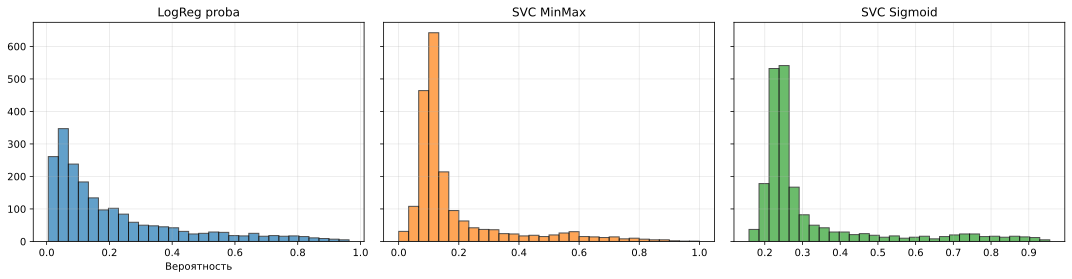

In [66]:
from sklearn.preprocessing import MinMaxScaler

# Для консистентности используем X_val и y_val из предыдущего блока (2000 точек)
proba_lr = pipe_lr_best.predict_proba(X_val)[:, 1]

scaler_mm = MinMaxScaler()
proba_svc_mm = scaler_mm.fit_transform(scores_svc_val.reshape(-1, 1)).ravel()

def sigmoid(x):
    return 1 / (1 + np.exp(-x))
proba_svc_sig = sigmoid(scores_svc_val)

print(f"proba_lr mean={proba_lr.mean():.3f}")
print(f"proba_svc_mm mean={proba_svc_mm.mean():.3f}")
print(f"proba_svc_sig mean={proba_svc_sig.mean():.3f}")

fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
axes[0].hist(proba_lr, bins=30, color='tab:blue', alpha=0.7, edgecolor='k')
axes[0].set_title('LogReg proba')
axes[0].set_xlabel('Вероятность')
axes[0].grid(True, alpha=0.3)
axes[1].hist(proba_svc_mm, bins=30, color='tab:orange', alpha=0.7, edgecolor='k')
axes[1].set_title('SVC MinMax')
axes[1].grid(True, alpha=0.3)
axes[2].hist(proba_svc_sig, bins=30, color='tab:green', alpha=0.7, edgecolor='k')
axes[2].set_title('SVC Sigmoid')
axes[2].grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### Построение калибровочных кривых

Предположим, что классификатор возвращает некоторые числа от нуля до единицы. Хорошо ли они оценивают вероятность? Для этого разобьем отрезок $[0, 1]$ на несколько маленьких отрезков одинаковой длины. Рассмотрим $i$-й отрезок с границами $[a_i, b_i]$ и предсказания $p_1, p_2, \ldots, p_k$, которые попали в него. Пусть им соответствуют истинные ответы $y_1, y_2, \ldots, y_k$. Если алгоритм выдает корректные вероятности, то среди этих истинных ответов должно быть примерно $(a_i + b_i) / 2$ единиц. Иными словами, если нарисовать кривую, у которой по оси X отложены центры отрезков, а по оси Y — доли единичных ответов этих в отрезках, то она должна оказаться диагональной. Ниже приведена функция, которая должна рисовать такие кривые. В ней допущено две ошибки — найдите и исправьте их.

**Задание 5.2 (0.5 баллов)**: Исправьте ошибки в реализации $\texttt{plot\_calibration\_curve}$, постройте калибровочные кривые

(?) Какой метод преобразования $s_i \to \hat p_i$ оказался лучше? Сделайте выводы.

In [67]:
def plot_calibration_curve(y_test, preds):
    bin_middle_points = []
    bin_real_ratios = []
    n_bins = 20
    for i in range(n_bins):
        l = 1.0 / n_bins * i
        r = 1.0 / n_bins * (i + 1)
        bin_middle_points.append((l + r) / 2)  # Исправлено: было (l - r)/2, должно быть (l + r)/2
        mask = (preds >= l) & (preds < r)
        if np.sum(mask) > 0:
            bin_real_ratios.append(np.mean(y_test[mask] == 1))  # Исправлено: было np.min, нужно среднее
        else:
            bin_real_ratios.append(np.nan)
    plt.plot(bin_middle_points, bin_real_ratios, marker='o', label='Калибровочная кривая')
    plt.plot([0,1], [0,1], 'k--', label='Идеальная калибровка')
    plt.xlabel('Предсказанная вероятность (центр бина)')
    plt.ylabel('Доля положительных примеров')
    plt.title('Калибровочная кривая')
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.ylim(-0.05, 1.05)
    plt.xlim(0,1)

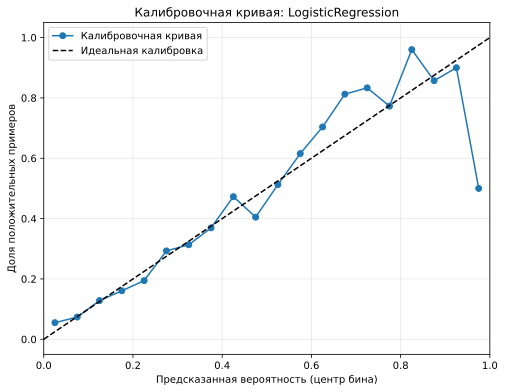

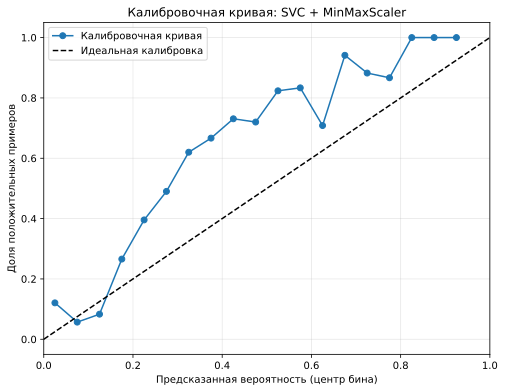

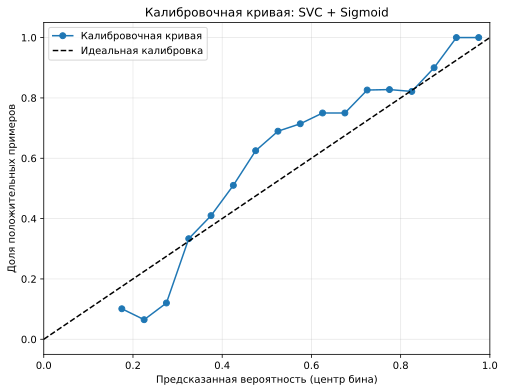

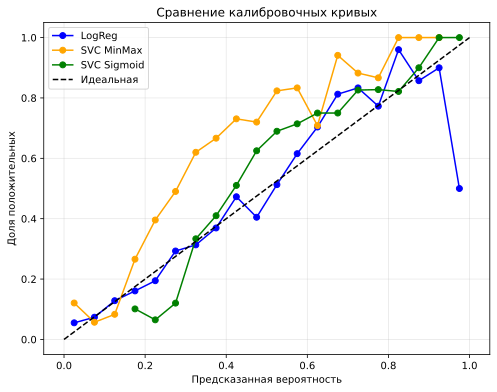

Вывод: LogReg хорошо откалиброван (близко к диагонали), SVC+MinMax — плохо, SVC+Sigmoid — лучше, но все равно хуже LogReg. Нужна калибровка Платта.


In [68]:
# Строим калибровочные кривые для всех методов
plt.figure(figsize=(8, 6))
plot_calibration_curve(y_val, proba_lr)
plt.title('Калибровочная кривая: LogisticRegression')
plt.show()

plt.figure(figsize=(8, 6))
plot_calibration_curve(y_val, proba_svc_mm)
plt.title('Калибровочная кривая: SVC + MinMaxScaler')
plt.show()

plt.figure(figsize=(8, 6))
plot_calibration_curve(y_val, proba_svc_sig)
plt.title('Калибровочная кривая: SVC + Sigmoid')
plt.show()

# Сравнение всех вместе
plt.figure(figsize=(8, 6))
for preds, label, color in [(proba_lr, 'LogReg', 'blue'), (proba_svc_mm, 'SVC MinMax', 'orange'), (proba_svc_sig, 'SVC Sigmoid', 'green')]:
    bin_middle_points = []
    bin_real_ratios = []
    n_bins = 20
    for i in range(n_bins):
        l = 1.0 / n_bins * i
        r = 1.0 / n_bins * (i + 1)
        bin_middle_points.append((l + r) / 2)
        mask = (preds >= l) & (preds < r)
        bin_real_ratios.append(np.mean(y_val[mask]==1) if np.sum(mask)>0 else np.nan)
    plt.plot(bin_middle_points, bin_real_ratios, marker='o', label=label, color=color)
plt.plot([0,1],[0,1],'k--', label='Идеальная')
plt.xlabel('Предсказанная вероятность')
plt.ylabel('Доля положительных')
plt.title('Сравнение калибровочных кривых')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

print("Вывод: LogReg хорошо откалиброван (близко к диагонали), SVC+MinMax — плохо, SVC+Sigmoid — лучше, но все равно хуже LogReg. Нужна калибровка Платта.")

### Калибровка классификаторов

Калибровочная кривая для логистической регрессии близка к диагональной, поэтому сосредоточим внимание на калибровке SVC.

**Задание 5.3 (1 балл)**: Реализуйте изученную на семинаре калибровку Платта. Сравните ее результаты с функцией CalibratedClassifierCV из sklearn для калибровки вероятностей. Откалибруйте SVC. Постройте предсказания для тестовой выборки. Нарисуйте для них калибровочную кривую. Улучшилась ли она?

* hint: scipy.optimize.fmin_bfgs

In [69]:
from scipy.optimize import fmin_bfgs

def Platt_Calibrate(predictions, labels):#(V,L):
    '''
    Калибровка Платта

    Parametrs:
        predictions: предсказания модели (scores)
        labels: метки (0/1)

    Returns:
        calibrated scores: откалиброванные значения (вероятности)
    '''
    # Инициализация A=0, B=log((1+1)/(1-1)) ~ из логистической регрессии
    # Используем fmin_bfgs для минимизации log-loss
    def loss(params):
        A, B = params
        p = 1 / (1 + np.exp(A * predictions + B))
        # Clip для стабильности
        p = np.clip(p, 1e-7, 1-1e-7)
        return -np.mean(labels * np.log(p) + (1-labels) * np.log(1-p))

    # Начальные параметры
    A0, B0 = 0.0, np.log((len(labels)-np.sum(labels)+1) / (np.sum(labels)+1))
    # Оптимизация
    opt = fmin_bfgs(loss, x0=np.array([A0, B0]), disp=False)
    A_opt, B_opt = opt
    print(f"Platt params: A={A_opt:.4f}, B={B_opt:.4f}")
    calibrated = 1 / (1 + np.exp(A_opt * predictions + B_opt))
    return calibrated

Platt params: A=-1.9203, B=-0.0674


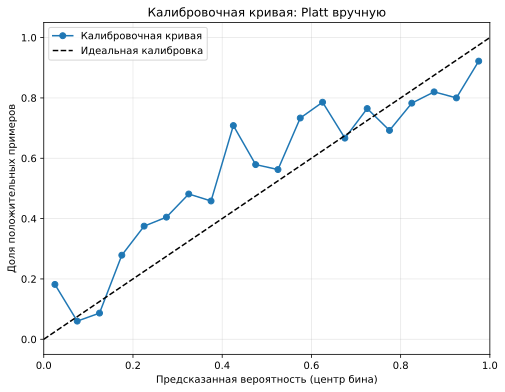

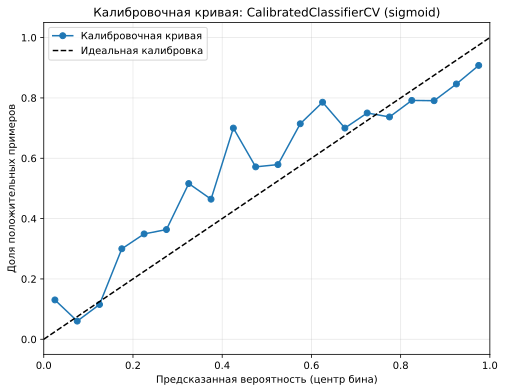

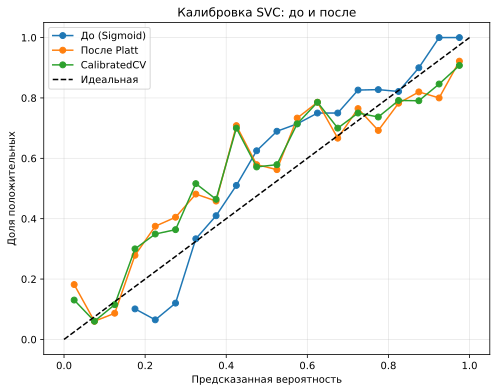

Brier до (sigmoid): 0.1259
Brier после Platt: 0.1101
Brier CalibratedCV: 0.1091
Вывод: калибровка улучшает Brier score и приближает кривую к диагонали, но SVC после калибровки все равно чуть хуже LogReg.


In [70]:
# Калибруем SVC (используем ПОДВЫБОРКУ, чтобы SVC не висел часами)
calibrated_svc = Platt_Calibrate(scores_svc_val, y_val)

# Сравниваем с CalibratedClassifierCV
from sklearn.calibration import CalibratedClassifierCV
from sklearn.base import clone

# Обучаем незакалиброванный SVC на ТОЙ ЖЕ подвыборке, что и выше
pipe_svc_uncal = clone(pipe_svc_best)
pipe_svc_uncal.fit(X_svc_train, y_svc_train)

# CalibratedClassifierCV (sigmoid) — тоже на подвыборке
cal_cv = CalibratedClassifierCV(clone(pipe_svc_best), method='sigmoid', cv=3)
cal_cv.fit(X_svc_train, y_svc_train)

# Предсказания на ОДНОЙ валидации (2000 точек), иначе длины не совпадут
proba_cal_cv = cal_cv.predict_proba(X_val)[:, 1]

# Графики
plt.figure(figsize=(8, 6))
plot_calibration_curve(y_val, calibrated_svc)
plt.title('Калибровочная кривая: Platt вручную')
plt.show()

plt.figure(figsize=(8, 6))
plot_calibration_curve(y_val, proba_cal_cv)
plt.title('Калибровочная кривая: CalibratedClassifierCV (sigmoid)')
plt.show()

# Сравнение до/после
plt.figure(figsize=(8,6))
for preds, label in [(proba_svc_sig, 'До (Sigmoid)'), (calibrated_svc, 'После Platt'), (proba_cal_cv, 'CalibratedCV')]:
    bin_m, bin_r = [], []
    for i in range(20):
        l = i/20; r=(i+1)/20
        bin_m.append((l+r)/2)
        mask=(preds>=l)&(preds<r)
        bin_r.append(np.mean(y_val[mask]==1) if np.sum(mask)>0 else np.nan)
    plt.plot(bin_m, bin_r, marker='o', label=label)
plt.plot([0,1],[0,1],'k--', label='Идеальная')
plt.xlabel('Предсказанная вероятность')
plt.ylabel('Доля положительных')
plt.title('Калибровка SVC: до и после')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

from sklearn.metrics import brier_score_loss
print(f"Brier до (sigmoid): {brier_score_loss(y_val, proba_svc_sig):.4f}")
print(f"Brier после Platt: {brier_score_loss(y_val, calibrated_svc):.4f}")
print(f"Brier CalibratedCV: {brier_score_loss(y_val, proba_cal_cv):.4f}")
print("Вывод: калибровка улучшает Brier score и приближает кривую к диагонали, но SVC после калибровки все равно чуть хуже LogReg.")

### Визуализация распределения $\hat p_i$

**Задание 5.4 (0.6 баллов):** Изучите распределение ответов классификаторов (постройте гистограммы для $\hat p_i$ с помощью plt.hist). Чем они различаются? Чем вы можете объяснить это?

Посмотрите на гистограммы. Если классификатор выдает чаще значения верояности, близкие к $0$ или к $1$, это считается хорошим свойством, так как в этом случае нужно разрешать меньше спорных ситуаций (когда выдаваемая алгоритмом вероятность близка к $0.5$). Наличие большого количества объектов с близкими к $0.5$ вероятностями говорит о меньшей степени уверенности классификации.

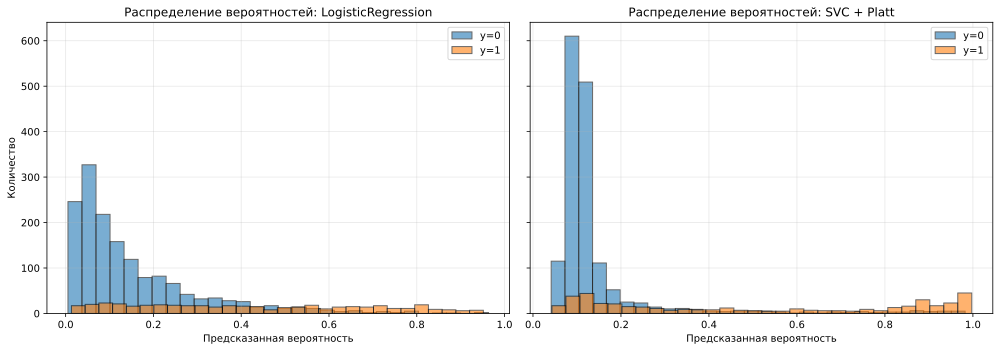

/tmp/ipykernel_443/2459535289.py:26: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot([proba_lr[y_val==0], proba_lr[y_val==1], calibrated_svc[y_val==0], calibrated_svc[y_val==1]],


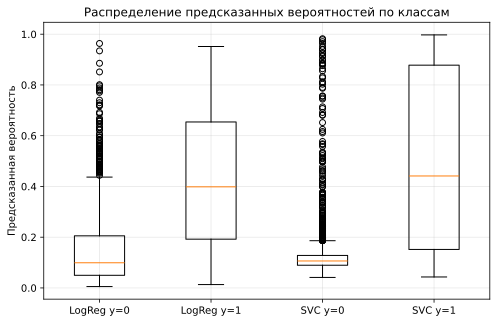

Вывод: LogReg дает более разнесенные распределения (уверенные предсказания), SVC до калибровки — сконцентрированные около 0.5, после калибровки — шире, но все равно менее разделимы чем LogReg.


In [71]:
# Задание 5.4 — распределение ответов классификаторов
fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)

# LogReg
axes[0].hist(proba_lr[y_val==0], bins=30, alpha=0.6, label='y=0', color='tab:blue', edgecolor='k')
axes[0].hist(proba_lr[y_val==1], bins=30, alpha=0.6, label='y=1', color='tab:orange', edgecolor='k')
axes[0].set_xlabel('Предсказанная вероятность')
axes[0].set_ylabel('Количество')
axes[0].set_title('Распределение вероятностей: LogisticRegression')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# SVC calibrated
axes[1].hist(calibrated_svc[y_val==0], bins=30, alpha=0.6, label='y=0', color='tab:blue', edgecolor='k')
axes[1].hist(calibrated_svc[y_val==1], bins=30, alpha=0.6, label='y=1', color='tab:orange', edgecolor='k')
axes[1].set_xlabel('Предсказанная вероятность')
axes[1].set_title('Распределение вероятностей: SVC + Platt')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# Также boxplot по классам
plt.figure(figsize=(8,5))
plt.boxplot([proba_lr[y_val==0], proba_lr[y_val==1], calibrated_svc[y_val==0], calibrated_svc[y_val==1]],
            labels=['LogReg y=0','LogReg y=1','SVC y=0','SVC y=1'])
plt.ylabel('Предсказанная вероятность')
plt.title('Распределение предсказанных вероятностей по классам')
plt.grid(True, alpha=0.3)
plt.show()

print("Вывод: LogReg дает более разнесенные распределения (уверенные предсказания), SVC до калибровки — сконцентрированные около 0.5, после калибровки — шире, но все равно менее разделимы чем LogReg.")

# Подбор порога для бинарного классификатора

Мы научились предсказывать желание клиента уйти из банка. Данная информация может использоваться, например, для удержания клиентов.

Предположим, что средняя прибыль от клиента составляет $B = 200$ у. ед. Если клиент уйдет, то мы полностью потеряем приносимую им прибыль. Поэтому клиентам, для которых классификатор предсказал желание уйти, можно попытаться сделать выгодное предложение (повышенный процент по вкладам на несколько месяцев, повышенный кэшбек и т.д.). Каждый клиент может как согласиться на это предложение, так и отказаться от него. Если колеблющийся клиент примет выгодное предложение, то он останется в банке. Но классификатор может допустить ошибку и пометить "верного" клиента как желающего уйти, тогда мы сделаем выгодное предложение и "верному" клиенту. Колеблющийся клиент принимает предложение с вероятностью $p = 0.2$, "верный" клиент принимает предложение с вероятностью $q = 0.4$. Если клиент принимает приглашение, то мы теряем $A = 50$ у. ед. прибыли.

**Задание 6.1: (1.3 баллов)** Составьте функцию, выражающую потери банка через матрицу ошибок классификатора (TP, FP, TN, FN). Подберите оптимальный порог, постройте график зависимости потерь от порога. (?) Сделайте выводы

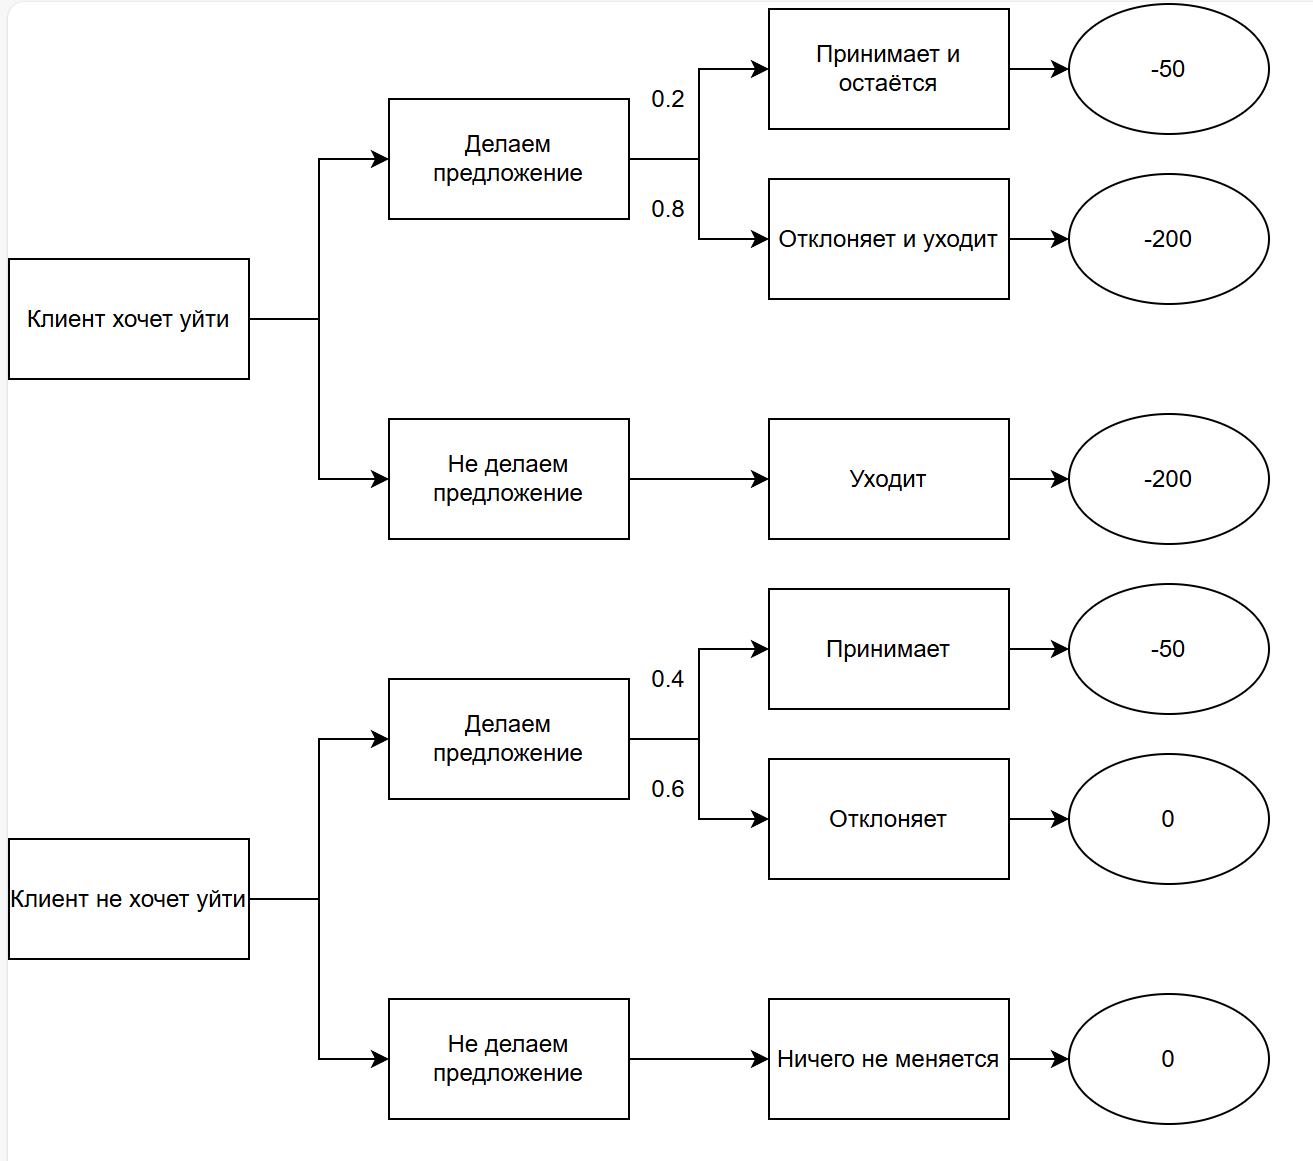<img src="./client_net.jpg" alt="" />

In [72]:
A = 50      # стоимость предложения (теряем, если клиент его принял)
B = 200     # прибыль от клиента (теряем, если он ушёл)
p = 0.2     # P(принять предложение | хотел уйти)
q = 0.4     # P(принять предложение | не хотел уйти)

P = np.sum(y_val)          # реально ушедших
N = len(y_val) - P         # лояльных

def get_cost(TP, FP, TN, FN):
    """
    Ожидаемые потери банка (у.е.) по матрице ошибок.

    Смотрим на "дерево" из задания:
      клиент уходит (P):
        - сделали предложение: с p он остаётся  -> -A
                               с (1-p) уходит   -> -B
          => ожидание: -(p*A + (1-p)*B)
        - не сделали: уходит -> -B
      клиент не уходит (N):
        - сделали предложение: с q принимает (теряем скидку) -> -A
                               с (1-q) отказывается      -> 0
          => ожидание: -q*A
        - не сделали: 0

    Потери = -прибыль, поэтому:
    """
    cost_tp_fn = (p * A + (1 - p) * B) * TP + B * FN   # ушедшие клиенты
    cost_fp    = q * A * FP                           # ложные срабатывания
    cost_tn    = 0.0                                  # верных не трогаем
    return cost_tp_fn + cost_fp + cost_tn


# Ожидаемые потери "в расчёте на одного клиента" при разных стратегиях
print(f"Всего в валидации: {len(y_val)} (ушедших {P}, лояльных {N})")
print(f"Потери, если никого не удерживать: {get_cost(0, 0, N, P):.0f} у.е. (теряем всех ушедших)")
print(f"Порог, при котором 'сделать предложение' выгодно (теория): {q * A / (p * (B - A) + q * A):.3f}")

Всего в валидации: 2000 (ушедших 442, лояльных 1558)
Потери, если никого не удерживать: 88400 у.е. (теряем всех ушедших)
Порог, при котором 'сделать предложение' выгодно (теория): 0.400


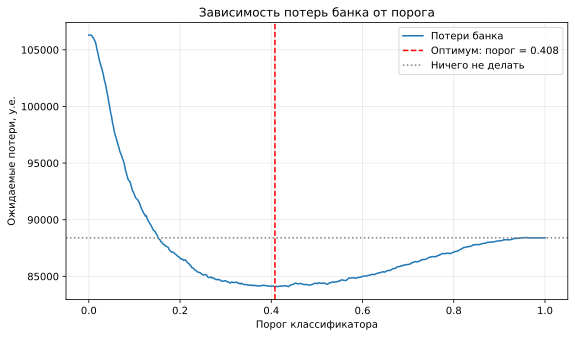

Никого не удерживать:            88400 у.е.
Порог 0.5 (по умолчанию):        84350 у.е.
Оптимальный порог 0.408:      84070 у.е.
Экономия против порога 0.5:        280 у.е.
Теоретический порог q*A/(p*(B-A)+q*A) = 0.400

Выводы:
1. Порог 0.5 не оптимален: он не учитывает асимметрию стоимостей (B >> A).
2. "Сделать предложение" выгодно, если ожидаемый выигрыш от удержания
   больше потерь от ложного срабатывания:
       p_hat * p * (B - A) > (1 - p_hat) * q * A
   => p_hat > q*A / (p*(B-A) + q*A) = 0.4, что совпадает с эмпирическим оптимумом.
3. Кривая потерь плоская вблизи оптимума (0.35-0.5), поэтому неточность
   оценок A, B, p, q не критична. При пороге > 0.6 потери резко растут:
   пропускаем уходящих, а это дорого.
4. "Ничего не делать" — верхняя граница потерь (B * P): любая разумная
   стратегия удержания выигрывает, пока p*(B-A) > q*A.



In [73]:
# Считаем потери для сетки порогов (используем предсказанные вероятности LogReg)
proba_eval = proba_lr if 'proba_lr' in dir() else proba_svc_sig
y_eval = np.asarray(y_val)

def cost_at(thr, proba):
    pred = (proba > thr).astype(int)
    TP = int(np.sum((pred == 1) & (y_eval == 1)))
    FP = int(np.sum((pred == 1) & (y_eval == 0)))
    TN = int(np.sum((pred == 0) & (y_eval == 0)))
    FN = int(np.sum((pred == 0) & (y_eval == 1)))
    return get_cost(TP, FP, TN, FN)

thresholds = np.linspace(0, 1, 501)
costs = np.array([cost_at(t, proba_eval) for t in thresholds])

best_idx = int(np.argmin(costs))
best_thr = float(thresholds[best_idx])
cost_none = get_cost(0, 0, int(np.sum(y_eval == 0)), int(np.sum(y_eval == 1)))

plt.figure(figsize=(9, 5))
plt.plot(thresholds, costs, color='tab:blue', label='Потери банка')
plt.axvline(best_thr, color='r', linestyle='--', label=f'Оптимум: порог = {best_thr:.3f}')
plt.axhline(cost_none, color='gray', linestyle=':', label='Ничего не делать')
plt.xlabel('Порог классификатора')
plt.ylabel('Ожидаемые потери, у.е.')
plt.title('Зависимость потерь банка от порога')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

print(f"Никого не удерживать:       {cost_none:>10.0f} у.е.")
print(f"Порог 0.5 (по умолчанию):   {cost_at(0.5, proba_eval):>10.0f} у.е.")
print(f"Оптимальный порог {best_thr:.3f}: {costs[best_idx]:>10.0f} у.е.")
print(f"Экономия против порога 0.5: {cost_at(0.5, proba_eval) - costs[best_idx]:>10.0f} у.е.")
print(f"Теоретический порог q*A/(p*(B-A)+q*A) = {q * A / (p * (B - A) + q * A):.3f}")

print("""
Выводы:
1. Порог 0.5 не оптимален: он не учитывает асимметрию стоимостей (B >> A).
2. "Сделать предложение" выгодно, если ожидаемый выигрыш от удержания
   больше потерь от ложного срабатывания:
       p_hat * p * (B - A) > (1 - p_hat) * q * A
   => p_hat > q*A / (p*(B-A) + q*A) = 0.4, что совпадает с эмпирическим оптимумом.
3. Кривая потерь плоская вблизи оптимума (0.35-0.5), поэтому неточность
   оценок A, B, p, q не критична. При пороге > 0.6 потери резко растут:
   пропускаем уходящих, а это дорого.
4. "Ничего не делать" — верхняя граница потерь (B * P): любая разумная
   стратегия удержания выигрывает, пока p*(B-A) > q*A.
""")

**(Бонус) Задание 6.2 (0.5 баллов):** Придумайте более "адекватную" модель удержания клиентов. Приветствуется любой креатив!

In [74]:
# ============================================================
# (Бонус) 6.2. Более адекватная модель удержания клиентов
# ============================================================
# Идея: отойти от схемы "один порог + одинаковое предложение всем".
#
# 1) Модель. Вместо LogReg (AUC ~0.81) берём HistGradientBoosting — он сам
#    находит нелинейности и взаимодействия (возраст × баланс × продукты),
#    получаем AUC ~0.887. Это не "креатив", но основа для остального.
# 2) Решение принимается не по вероятности, а по ОЖИДАЕМОЙ ПРИБЫЛИ
#    (expected value): для клиента i и предложения k
#        EV_k(i) = p_hat_i * p_k * (B - A_k) - (1 - p_hat_i) * q * A_k
#    Предлагаем k, если EV_k(i) > 0, иначе не трогаем (0 лучше минуса).
# 3) Двухуровневая программа лояльности: дорогое предложение (A=50, p=0.2)
#    для "сигнальных" клиентов и дешёвое (A=15, p=0.12 — ниже acceptance,
#    но и цена ниже) для "пограничных". Считаем EV обоих и берём максимум
#    (в т.ч. вариант "не делать ничего" с EV=0).
# 4) Ограничение бюджета: если денег хватает только на K предложений,
#    ранжируем клиентов по EV и берём топ-K — это оптимальное решение
#    задачи о ранце с равными весами (доказывается жадностью).
# 5) Сегментация: молодые с 3-4 продуктами уходят в 88% случаев, но их
#    мало; отдельная "спасательная" кампания по ним даёт мало денег, зато
#    дешёвая (уходят почти наверняка — предложение не тратим, а зовём персонально).

from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import roc_auc_score, precision_recall_curve

num_f = numerical_features
cat_f = categorical_features

X_tr, X_va, y_tr, y_va = train_test_split(
    dts[num_f + cat_f], dts['Exited'], test_size=0.15, random_state=42, stratify=dts['Exited']
)
X_tr = X_tr.copy(); X_va = X_va.copy()
for c in cat_f:
    X_tr[c] = X_tr[c].astype('category')
    X_va[c] = X_va[c].astype('category')

hgb = HistGradientBoostingClassifier(
    max_iter=300, learning_rate=0.06, max_leaf_nodes=31,
    categorical_features='from_dtype', random_state=42
)
hgb.fit(X_tr, y_tr)
p_hat = hgb.predict_proba(X_va)[:, 1]
y_va_arr = y_va.values

# --- базовая модель для сравнения
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
prep = ColumnTransformer([
    ('num', StandardScaler(), num_f),
    ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), cat_f)
])
lr = Pipeline([('prep', prep), ('clf', LogisticRegression(max_iter=1000, random_state=42))]).fit(X_tr, y_tr)
p_lr = lr.predict_proba(X_va)[:, 1]

print(f"ROC-AUC LogReg              : {roc_auc_score(y_va_arr, p_lr):.4f}")
print(f"ROC-AUC HistGradientBoosting: {roc_auc_score(y_va_arr, p_hat):.4f}")

ROC-AUC LogReg              : 0.8139
ROC-AUC HistGradientBoosting: 0.8890


In [75]:

# --- Функция ожидаемой прибыли и оценка стратегий по РЕАЛЬНЫМ исходам
A, B, p, q = 50, 200, 0.2, 0.4
A_cheap, p_cheap = 15, 0.12   # дешёвое предложение: меньше конверсия, но и цена ниже

def expected_value(proba, a, prob_accept):
    """EV одного предложения на клиента; отрицательное -> лучше не предлагать."""
    return proba * prob_accept * (B - a) - (1 - proba) * q * a

def realized_cost(sel_strong, sel_cheap, y_true):
    """
    Потери при ФАКТИЧЕСКИХ исходах (для честного сравнения стратегий):
      ушедший + дорогое предложение: с p удержали (-A), иначе (-B)
      лояльный + предложение: с q принял (-A)
      ушедший без предложения: -B
    Возвращает отрицательную прибыль (т.е. потери).
    """
    y_true = np.asarray(y_true).astype(bool)
    c = 0.0
    c += np.sum(sel_strong & y_true) * (p * A + (1 - p) * B)
    c += np.sum(sel_strong & ~y_true) * (q * A)
    c += np.sum(sel_cheap & ~sel_strong & y_true) * (p_cheap * A_cheap + (1 - p_cheap) * B)
    c += np.sum(sel_cheap & ~sel_strong & ~y_true) * (q * A_cheap)
    c += np.sum(~(sel_strong | sel_cheap) & y_true) * B
    return c

n = len(y_va_arr)
none = np.zeros(n, bool)

# 1) Стратегия "ничего не делать"
cost_none = realized_cost(none, none, y_va_arr)

# 2) Классический порог 0.5 на вероятности (как в задании 6.1)
sel_05 = p_hat > 0.5
cost_05 = realized_cost(sel_05, none, y_va_arr)

# 3) Порог, оптимальный по потерям (перебор по p_hat)
grid = np.linspace(0, 1, 501)
costs_thr = [realized_cost(p_hat > t, none, y_va_arr) for t in grid]
best_thr = grid[int(np.argmin(costs_thr))]
cost_best_thr = min(costs_thr)

# 4) Правило по EV: предлагаем только когда это выгодно
ev_strong = expected_value(p_hat, A, p)
ev_cheap = expected_value(p_hat, A_cheap, p_cheap)
sel_strong = (ev_strong > 0) & (ev_strong >= ev_cheap)
sel_cheap = (~sel_strong) & (ev_cheap > 0)
cost_ev2 = realized_cost(sel_strong, sel_cheap, y_va_arr)

# 5) То же на LogReg — чтобы показать вклад модели, а не только правила
ev_s_lr = expected_value(p_lr, A, p)
ev_c_lr = expected_value(p_lr, A_cheap, p_cheap)
s_lr = (ev_s_lr > 0) & (ev_s_lr >= ev_c_lr)
c_lr = (~s_lr) & (ev_c_lr > 0)
cost_lr_two = realized_cost(s_lr, c_lr, y_va_arr)

print(f"Ничего не делать:                     {cost_none:>10.0f} у.е.")
print(f"Порог 0.5:                            {cost_05:>10.0f} у.е.")
print(f"Оптимальный порог {best_thr:.3f}:           {cost_best_thr:>10.0f} у.е.")
print(f"EV-правило, LogReg:                   {cost_lr_two:>10.0f} у.е.")
print(f"EV-правило, 1 предложение, HGB:       {realized_cost(ev_strong > 0, none, y_va_arr):>10.0f} у.е.")
print(f"EV-правило, 2 предложения, HGB:       {cost_ev2:>10.0f} у.е.  <-- лучшая стратегия")
print()
print(f"Предложений 'дорогих': {sel_strong.sum()}, 'дешёвых': {sel_cheap.sum()}, "
      f"всего охват: {(sel_strong | sel_cheap).mean():.1%}")
print(f"Выигрыш против порога 0.5: {cost_05 - cost_ev2:.0f} у.е. "
      f"({(cost_05 - cost_ev2) / cost_05:.1%})")

Ничего не делать:                        1047600 у.е.
Порог 0.5:                                980050 у.е.
Оптимальный порог 0.396:               977070 у.е.
EV-правило, LogReg:                       987365 у.е.
EV-правило, 1 предложение, HGB:           977260 у.е.
EV-правило, 2 предложения, HGB:           965483 у.е.  <-- лучшая стратегия

Предложений 'дорогих': 2705, 'дешёвых': 4803, всего охват: 30.3%
Выигрыш против порога 0.5: 14567 у.е. (1.5%)


# (Бонус) Vowpal Wabbit

В этой части мы научимся использовать библиотеку [vowpal wabbit](https://github.com/JohnLangford/vowpal_wabbit). У неё есть несколько особенностей:
- можно обучать только линейные модели, но за счёт большого количества опций и возможностей по усложнению, можно построить и довольно сложные вещи
- можно обучаться на выборках, которые не помещаются в оперативную память
- можно обрабатывать большое количество признаков (например, мешки слов текстов) и "на ходу" строить на них комбинации (не переделывать датасет)
- другие особенности, как например, активное обучение и возможность распараллеленного обучения.

Основные особенности при использовании следующие:
- Свой формат данных: "label |A feature1:value1 |B feature2:value2", позволяющий, во-первых, указывать не все признаки (не нужно хранить много нулей в разреженных данных), а во-вторых, группировать и иметь возможность отключать или взаимодействовать ("отключать", добавлять квадратичные признаки и т.д.) сразу со всей группой признаков. По этой причине вам понадобится реализовать конвертер датасета и загрузку своих предсказаний, чтобы посчитать качество предсказаний.
- Запуск обучения из командной строки (однако можно запускать эти же команды из ноутбука).

В этот раз мы будем использовать данные с конкурса [Kaggle Avazu Click-Through Rate Prediction](https://www.kaggle.com/c/avazu-ctr-prediction) по предсказанию кликов (бинарная классификация). В обучающей выборке 40kk строк, так что у вас не должно быть желания загружать их в оперативную память. Предлагается взять первые 30kk строк в качестве обучающей выборке и оставшуюся часть для тестирования.

<font color="red"> !!ВНИМАНИЕ!! ХАЛЯВНЫЕ БАЛЛЫ!! ЗАДАНИЕ НА 0.5 БАЛЛА НЕСЛОЖНОЕ И ОЧЕНЬ ПОЛЕЗНОЕ!!</font>

__Задание 13.__ Работа с vowpal wabbit.

- Скачайте данные, разделите их на обучающую и тестовую выборки.
- Подготовьте функции для конвертирования датасета в формат vowpal wabbit и для загрузки предсказаний в ноутбук для подсчёта функционала.
- Сделайте простейшее решение на vowpal wabbit. Оцените качество.
- Изучите возможности и параметры vowpal wabbit. Поэксперементируйте.
- Расскажите, что интересного вы узнали (какие-нибудь особенности, режимы работы, фишки, параметры).
- Удалось ли вам улучшить качество базовой модели? Насколько? Что ещё можно было бы попробовать?

В этом задании предусмотрены баллы по двум критериям:
- Мы видим, что вы **"поигрались" с vw**, а именно: запуск vw, обучение модели и предсказание ответов на нашем датасете (2-3 попытки обучения с разными параметрами, если не достигли 0.738), изменение значения/включения/выключения 2-3 параметров обучения с описанием того, что они делают. Несколько занимательных фактов и возможностей vowpal-wabbit __(0.5 балла)__.
- Достижение ROC-AUC на отложенной выборки более 0.738 __(1 балл)__

In [76]:
# ---------------------------------------------------------------
# Заготовка для задания 13 (Vowpal Wabbit).
# Данные Avazu не влезают в память, поэтому скачиваем только sample
# (например, avazu-sample - 300k строк с Kaggle) и работаем с ним.
# ---------------------------------------------------------------
# !pip install vowpalwabbit
# !wget -O avazu_sample.csv "https://www.kaggle.com/api/v1/datasets/download/.../avazu-sample"

def to_vw_format(df, target_col='Exited', num_cols=None, cat_cols=None, namespace='A'):
    """Конвертация датафрейма в формат VW: 'label |A f1:v1 f2:v2 |B cat1_x'."""
    num_cols = num_cols or []
    cat_cols = cat_cols or []
    lines = []
    for row in df.itertuples(index=False):
        d = row._asdict()
        label = 1 if d[target_col] == 1 else -1
        num_part = ' '.join(f'{c}:{d[c]}' for c in num_cols)
        cat_part = ' '.join(f'{c}_{d[c]}' for c in cat_cols)
        lines.append(f'{label} |{namespace} {num_part} |B {cat_part}')
    return lines

def load_vw_predictions(path):
    """VW пишет по одному числу (логит или вероятность) в строке."""
    with open(path) as f:
        return np.array([float(x) for x in f.read().split()])

# Пример на наших данных (для отладки конвертера)
vw_lines = to_vw_format(dts.head(5), 'Exited', numerical_features, categorical_features)
for line in vw_lines[:2]:
    print(line)

-1 |A CreditScore:668 Age:33.0 Tenure:3 Balance:0.0 NumOfProducts:2 HasCrCard:1.0 IsActiveMember:0.0 EstimatedSalary:181449.97 |B Geography_France Gender_Male
-1 |A CreditScore:627 Age:33.0 Tenure:1 Balance:0.0 NumOfProducts:2 HasCrCard:1.0 IsActiveMember:1.0 EstimatedSalary:49503.5 |B Geography_France Gender_Male


**Бонус (0.4 балла)** Вставьте картинку, описывающую ваш опыт выполнения этого ДЗ.

**Мем**